In [ ]:
# ============================================
# LSTM TRAINING — CELL 1
# Load Dataset
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

CSV_PATH = "/content/live_telemetry.csv"

df = pd.read_csv(CSV_PATH)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True
)

print("Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

display(df.head())

Dataset loaded successfully.
Rows    : 20,033
Columns : 30


,timestamp,experiment_id,vm_id,workload_profile,phase,workload_active,elapsed_seconds_since_previous_sample,guest_memory_total_mib,guest_memory_available_mib,guest_memory_used_mib,guest_memory_used_pct,guest_swap_total_mib,guest_swap_free_mib,guest_swap_used_mib,balloon_current_mib,balloon_maximum_mib,balloon_unused_mib,balloon_available_mib,balloon_usable_mib,balloon_rss_mib,balloon_swap_in_mib,balloon_swap_out_mib,vcpu_count,cpu_time_ns,cpu_utilization_pct,network_rx_bytes,network_tx_bytes,network_rx_bytes_per_sec,network_tx_bytes_per_sec,collection_errors
0,2026-10-08 12:00:27.472023+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,False,NaN,1863.808594,1445.765625,418.042969,22.429501,0.0,0.0,0.0,2048.0,4096.0,3796.636719,3870.800781,3681.089844,896.917969,0.0,0.0,2,23310769000,NaN,90,0,NaN,NaN,NaN
1,2026-10-08 12:00:32.541865+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,False,5.069840,1863.808594,1445.781250,418.027344,22.428663,0.0,0.0,0.0,2048.0,4096.0,3796.636719,3870.800781,3681.089844,896.917969,0.0,0.0,2,23337675000,0.265354,90,0,0.0,0.0,NaN
2,2026-10-08 12:00:37.626301+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,False,5.084437,1863.808594,1445.871094,417.937500,22.423842,0.0,0.0,0.0,2048.0,4096.0,3796.636719,3870.800781,3681.089844,896.917969,0.0,0.0,2,23364993000,0.268643,90,0,0.0,0.0,NaN
3,2026-10-08 12:00:42.702572+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,False,5.076271,1863.808594,1445.906250,417.902344,22.421956,0.0,0.0,0.0,2048.0,4096.0,3796.636719,3870.800781,3681.089844,896.917969,0.0,0.0,2,23394764000,0.293237,90,0,0.0,0.0,NaN
4,2026-10-08 12:00:47.770885+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,False,5.068314,1863.808594,1445.929688,417.878906,22.420699,0.0,0.0,0.0,2048.0,4096.0,3796.636719,3870.800781,3681.089844,896.917969,0.0,0.0,2,23421391000,0.262681,90,0,0.0,0.0,NaN


In [ ]:
# ============================================
# LSTM TRAINING — CELL 2
# Prepare Modeling Dataset
# ============================================

print("=" * 80)
print("PREPARING MODELING DATA")
print("=" * 80)

# ------------------------------------------------
# Configuration
# ------------------------------------------------

FEATURES = [
    "guest_memory_used_mib",
    "cpu_utilization_pct"
]

TARGET = "guest_memory_used_mib"

SEQUENCE_LENGTH = 6
FORECAST_HORIZON = 2

print("\nConfiguration:")
print(f"Input features     : {FEATURES}")
print(f"Target             : {TARGET}")
print(f"Sequence length    : {SEQUENCE_LENGTH}")
print(f"Forecast horizon   : {FORECAST_HORIZON}")
print(f"Approx history     : {SEQUENCE_LENGTH * 5.15:.2f} sec")
print(f"Approx forecast    : {FORECAST_HORIZON * 5.15:.2f} sec")


# ------------------------------------------------
# Create clean modeling dataframe
# ------------------------------------------------

model_df = df[
    [
        "timestamp",
        "experiment_id",
        "vm_id",
        "workload_profile",
        "phase"
    ] + FEATURES
].copy()

model_df = model_df.sort_values(
    ["timestamp", "vm_id"]
).reset_index(drop=True)


# ------------------------------------------------
# Remove rows with missing model features
# ------------------------------------------------

before = len(model_df)

model_df = model_df.dropna(
    subset=FEATURES
).reset_index(drop=True)

after = len(model_df)

print("\nMissing-feature handling:")
print(f"Rows before: {before:,}")
print(f"Rows removed: {before - after:,}")
print(f"Rows after : {after:,}")


# ------------------------------------------------
# Check target
# ------------------------------------------------

print("\nTarget statistics:")
print(
    model_df[TARGET]
    .describe()
    .round(4)
)


# ------------------------------------------------
# Basic integrity checks
# ------------------------------------------------

print("\n" + "=" * 80)
print("DATASET INTEGRITY")
print("=" * 80)

print(f"Rows              : {len(model_df):,}")
print(f"Experiments       : {model_df['experiment_id'].nunique():,}")
print(f"VMs               : {model_df['vm_id'].nunique()}")
print(f"Missing features  : {model_df[FEATURES].isna().sum().sum()}")
print(f"Missing target    : {model_df[TARGET].isna().sum()}")


# ------------------------------------------------
# Samples per VM
# ------------------------------------------------

print("\nRows by VM:")

display(
    model_df["vm_id"]
    .value_counts()
    .sort_index()
    .to_frame("rows")
)


# ------------------------------------------------
# Preview
# ------------------------------------------------

print("\nModeling data preview:")

display(
    model_df.head(10)
)


print("\n✅ Modeling dataset prepared.")

PREPARING MODELING DATA

Configuration:
Input features     : ['guest_memory_used_mib', 'cpu_utilization_pct']
Target             : guest_memory_used_mib
Sequence length    : 6
Forecast horizon   : 2
Approx history     : 30.90 sec
Approx forecast    : 10.30 sec

Missing-feature handling:
Rows before: 20,033
Rows removed: 770
Rows after : 19,263

Target statistics:
count    19263.0000
mean       458.4630
std         80.2176
min        393.8359
25%        410.7578
50%        420.4141
75%        470.8105
max        678.5508
Name: guest_memory_used_mib, dtype: float64

DATASET INTEGRITY
Rows              : 19,263
Experiments       : 410
VMs               : 3
Missing features  : 0
Missing target    : 0

Rows by VM:


,rows
vm_id,
testvm1,6428
testvm2,6407
testvm3,6428



Modeling data preview:


,timestamp,experiment_id,vm_id,workload_profile,phase,guest_memory_used_mib,cpu_utilization_pct
0,2026-10-08 12:00:32.541865+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,418.027344,0.265354
1,2026-10-08 12:00:37.626301+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,417.937500,0.268643
2,2026-10-08 12:00:42.702572+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,417.902344,0.293237
3,2026-10-08 12:00:47.770885+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,417.878906,0.262681
4,2026-10-08 12:00:52.837341+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,417.878906,0.221091
5,2026-10-08 12:00:57.901579+00:00,cca6cf44c46a,testvm1,memory_ramp,baseline,417.863281,0.276261
6,2026-10-08 12:00:58.110372+00:00,cca6cf44c46a,testvm1,memory_ramp,workload,417.863281,6.934496
7,2026-10-08 12:01:03.182603+00:00,cca6cf44c46a,testvm1,memory_ramp,workload,425.726562,0.274830
8,2026-10-08 12:01:08.258036+00:00,cca6cf44c46a,testvm1,memory_ramp,workload,441.714844,0.437736
9,2026-10-08 12:01:13.321576+00:00,cca6cf44c46a,testvm1,memory_ramp,workload,457.703125,0.450308



✅ Modeling dataset prepared.


In [ ]:
# ============================================
# LSTM TRAINING — CELL 3
# Chronological Experiment Split
# ============================================

print("=" * 80)
print("CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT")
print("=" * 80)

# ------------------------------------------------
# Determine chronological order of experiments
# ------------------------------------------------

experiment_order = (
    model_df
    .groupby("experiment_id")["timestamp"]
    .min()
    .sort_values()
)

experiment_ids = experiment_order.index.tolist()

total_experiments = len(experiment_ids)

print(f"Total experiments: {total_experiments}")


# ------------------------------------------------
# Split experiments chronologically
# ------------------------------------------------

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

train_end = int(total_experiments * TRAIN_RATIO)

val_end = train_end + int(
    total_experiments * VAL_RATIO
)

train_experiments = experiment_ids[:train_end]

val_experiments = experiment_ids[
    train_end:val_end
]

test_experiments = experiment_ids[
    val_end:
]


# ------------------------------------------------
# Create datasets
# ------------------------------------------------

train_df = model_df[
    model_df["experiment_id"].isin(train_experiments)
].copy()

val_df = model_df[
    model_df["experiment_id"].isin(val_experiments)
].copy()

test_df = model_df[
    model_df["experiment_id"].isin(test_experiments)
].copy()


# ------------------------------------------------
# Sort each split
# ------------------------------------------------

for split_df in [train_df, val_df, test_df]:

    split_df.sort_values(
        ["vm_id", "experiment_id", "timestamp"],
        inplace=True
    )

    split_df.reset_index(
        drop=True,
        inplace=True
    )


# ------------------------------------------------
# Print split information
# ------------------------------------------------

print("\n" + "=" * 80)
print("SPLIT SUMMARY")
print("=" * 80)

split_summary = pd.DataFrame({
    "split": [
        "train",
        "validation",
        "test"
    ],
    "experiments": [
        len(train_experiments),
        len(val_experiments),
        len(test_experiments)
    ],
    "rows": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "percentage_rows": [
        len(train_df) / len(model_df) * 100,
        len(val_df) / len(model_df) * 100,
        len(test_df) / len(model_df) * 100
    ]
})

display(
    split_summary.round(2)
)


# ------------------------------------------------
# Time boundaries
# ------------------------------------------------

print("\n" + "=" * 80)
print("TEMPORAL BOUNDARIES")
print("=" * 80)

boundary_summary = pd.DataFrame({
    "split": [
        "train",
        "validation",
        "test"
    ],
    "start": [
        train_df["timestamp"].min(),
        val_df["timestamp"].min(),
        test_df["timestamp"].min()
    ],
    "end": [
        train_df["timestamp"].max(),
        val_df["timestamp"].max(),
        test_df["timestamp"].max()
    ]
})

display(boundary_summary)


# ------------------------------------------------
# Verify experiment separation
# ------------------------------------------------

train_set = set(train_experiments)
val_set = set(val_experiments)
test_set = set(test_experiments)

print("\n" + "=" * 80)
print("LEAKAGE CHECK")
print("=" * 80)

print(
    "Train ∩ Validation:",
    len(train_set & val_set)
)

print(
    "Train ∩ Test:",
    len(train_set & test_set)
)

print(
    "Validation ∩ Test:",
    len(val_set & test_set)
)


# ------------------------------------------------
# VM distribution
# ------------------------------------------------

print("\n" + "=" * 80)
print("VM DISTRIBUTION")
print("=" * 80)

vm_split = pd.DataFrame({
    "train": train_df["vm_id"].value_counts(),
    "validation": val_df["vm_id"].value_counts(),
    "test": test_df["vm_id"].value_counts()
}).fillna(0).astype(int)

display(vm_split)


# ------------------------------------------------
# Workload distribution
# ------------------------------------------------

print("\n" + "=" * 80)
print("WORKLOAD DISTRIBUTION")
print("=" * 80)

workload_split = pd.DataFrame({
    "train": train_df["workload_profile"].value_counts(),
    "validation": val_df["workload_profile"].value_counts(),
    "test": test_df["workload_profile"].value_counts()
}).fillna(0).astype(int)

display(workload_split)


print("\n✅ Chronological split completed.")

CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
Total experiments: 410

SPLIT SUMMARY


,split,experiments,rows,percentage_rows
0,train,287,13503,70.10
1,validation,61,2835,14.72
2,test,62,2925,15.18



TEMPORAL BOUNDARIES


,split,start,end
0,train,2026-10-08 12:00:32.541865+00:00,2026-10-08 23:16:26.404161+00:00
1,validation,2026-10-08 23:16:31.773666+00:00,2026-10-09 01:24:53.293385+00:00
2,test,2026-10-09 01:24:58.837815+00:00,2026-10-09 03:40:32.013114+00:00



LEAKAGE CHECK
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

VM DISTRIBUTION


,train,validation,test
vm_id,,,
testvm1,4511,951,966
testvm2,4511,927,969
testvm3,4481,957,990



WORKLOAD DISTRIBUTION


,train,validation,test
workload_profile,,,
cpu_burst,2700,585,540
idle,2700,585,603
memory_burst,2711,561,606
memory_ramp,2711,513,612
mixed,2681,591,564



✅ Chronological split completed.


In [ ]:
# ============================================
# LSTM TRAINING — CELL 4
# Leakage-Free Feature Scaling
# ============================================

from sklearn.preprocessing import RobustScaler

print("=" * 80)
print("FEATURE SCALING")
print("=" * 80)

# ------------------------------------------------
# Create scalers
# ------------------------------------------------

feature_scaler = RobustScaler()
target_scaler = RobustScaler()


# ------------------------------------------------
# Fit ONLY on training data
# ------------------------------------------------

feature_scaler.fit(
    train_df[FEATURES]
)

target_scaler.fit(
    train_df[[TARGET]]
)


# ------------------------------------------------
# Transform train / validation / test
# ------------------------------------------------

train_scaled = train_df.copy()
val_scaled = val_df.copy()
test_scaled = test_df.copy()


train_scaled[FEATURES] = feature_scaler.transform(
    train_df[FEATURES]
)

val_scaled[FEATURES] = feature_scaler.transform(
    val_df[FEATURES]
)

test_scaled[FEATURES] = feature_scaler.transform(
    test_df[FEATURES]
)


# Target scaling
train_scaled[TARGET] = target_scaler.transform(
    train_df[[TARGET]]
).ravel()

val_scaled[TARGET] = target_scaler.transform(
    val_df[[TARGET]]
).ravel()

test_scaled[TARGET] = target_scaler.transform(
    test_df[[TARGET]]
).ravel()


# ------------------------------------------------
# Verify scaling
# ------------------------------------------------

print("\nFeature scaler center:")
print(feature_scaler.center_)

print("\nFeature scaler scale:")
print(feature_scaler.scale_)

print("\nTarget scaler center:")
print(target_scaler.center_)

print("\nTarget scaler scale:")
print(target_scaler.scale_)


# ------------------------------------------------
# Compare raw vs scaled training data
# ------------------------------------------------

print("\n" + "=" * 80)
print("TRAINING DATA — BEFORE SCALING")
print("=" * 80)

display(
    train_df[FEATURES]
    .describe()
    .T
    .round(4)
)


print("\n" + "=" * 80)
print("TRAINING DATA — AFTER SCALING")
print("=" * 80)

display(
    train_scaled[FEATURES]
    .describe()
    .T
    .round(4)
)


# ------------------------------------------------
# Verify validation/test were NOT used to fit
# ------------------------------------------------

print("\n" + "=" * 80)
print("SPLIT SIZES")
print("=" * 80)

print(f"Train      : {len(train_scaled):,}")
print(f"Validation : {len(val_scaled):,}")
print(f"Test       : {len(test_scaled):,}")


print("\n✅ Scalers fitted ONLY on training data.")
print("✅ Validation/test data transformed without refitting.")

FEATURE SCALING

Feature scaler center:
[418.58984375   0.42144345]

Feature scaler scale:
[60.41992188  0.32688327]

Target scaler center:
[418.58984375]

Target scaler scale:
[60.41992188]

TRAINING DATA — BEFORE SCALING


,count,mean,std,min,25%,50%,75%,max
guest_memory_used_mib,13503.0,457.3347,80.2944,393.8359,410.0566,418.5898,470.4766,678.5508
cpu_utilization_pct,13503.0,10.3492,19.6096,0.1150,0.3384,0.4214,0.6653,50.3314



TRAINING DATA — AFTER SCALING


,count,mean,std,min,25%,50%,75%,max
guest_memory_used_mib,13503.0,0.6413,1.3289,-0.4097,-0.1412,0.0,0.8588,4.3026
cpu_utilization_pct,13503.0,30.3709,59.9896,-0.9375,-0.2540,0.0,0.7460,152.6843



SPLIT SIZES
Train      : 13,503
Validation : 2,835
Test       : 2,925

✅ Scalers fitted ONLY on training data.
✅ Validation/test data transformed without refitting.


In [ ]:
# ============================================
# LSTM TRAINING — CELL 5
# Build Leakage-Safe LSTM Sequences
# ============================================

print("=" * 80)
print("BUILDING LSTM SEQUENCES")
print("=" * 80)

def create_sequences(
    data,
    features,
    target,
    sequence_length,
    forecast_horizon
):
    """
    Create LSTM sequences independently for each
    VM + experiment.

    Input:
        [t-sequence_length+1 ... t]

    Target:
        t + forecast_horizon

    Sequences are never allowed to cross:
        - VM boundaries
        - experiment boundaries
    """

    X = []
    y = []

    metadata = []

    # Process each experiment/VM independently
    grouped = data.groupby(
        ["vm_id", "experiment_id"],
        sort=False
    )

    for (vm_id, experiment_id), group in grouped:

        group = group.sort_values("timestamp").reset_index(drop=True)

        feature_values = group[features].values
        target_values = group[target].values

        timestamps = group["timestamp"].values
        workloads = group["workload_profile"].values
        phases = group["phase"].values

        max_start = (
            len(group)
            - sequence_length
            - forecast_horizon
            + 1
        )

        if max_start <= 0:
            continue

        for i in range(max_start):

            input_end = i + sequence_length
            target_index = (
                input_end + forecast_horizon - 1
            )

            # Input sequence
            X.append(
                feature_values[i:input_end]
            )

            # Future target
            y.append(
                target_values[target_index]
            )

            # Store metadata for analysis
            metadata.append({
                "vm_id": vm_id,
                "experiment_id": experiment_id,
                "input_start": timestamps[i],
                "input_end": timestamps[input_end - 1],
                "target_time": timestamps[target_index],
                "workload_profile": workloads[target_index],
                "phase": phases[target_index]
            })

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DataFrame(metadata)
    )


# ------------------------------------------------
# Create sequences
# ------------------------------------------------

X_train, y_train, meta_train = create_sequences(
    train_scaled,
    FEATURES,
    TARGET,
    SEQUENCE_LENGTH,
    FORECAST_HORIZON
)

X_val, y_val, meta_val = create_sequences(
    val_scaled,
    FEATURES,
    TARGET,
    SEQUENCE_LENGTH,
    FORECAST_HORIZON
)

X_test, y_test, meta_test = create_sequences(
    test_scaled,
    FEATURES,
    TARGET,
    SEQUENCE_LENGTH,
    FORECAST_HORIZON
)


# ------------------------------------------------
# Sequence shapes
# ------------------------------------------------

print("\n" + "=" * 80)
print("SEQUENCE SHAPES")
print("=" * 80)

print(f"X_train : {X_train.shape}")
print(f"y_train : {y_train.shape}")

print(f"X_val   : {X_val.shape}")
print(f"y_val   : {y_val.shape}")

print(f"X_test  : {X_test.shape}")
print(f"y_test  : {y_test.shape}")


# ------------------------------------------------
# Expected shape verification
# ------------------------------------------------

expected_features = len(FEATURES)

assert X_train.ndim == 3
assert X_val.ndim == 3
assert X_test.ndim == 3

assert X_train.shape[1] == SEQUENCE_LENGTH
assert X_val.shape[1] == SEQUENCE_LENGTH
assert X_test.shape[1] == SEQUENCE_LENGTH

assert X_train.shape[2] == expected_features
assert X_val.shape[2] == expected_features
assert X_test.shape[2] == expected_features

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)


# ------------------------------------------------
# Verify metadata alignment
# ------------------------------------------------

assert len(meta_train) == len(X_train)
assert len(meta_val) == len(X_val)
assert len(meta_test) == len(X_test)


# ------------------------------------------------
# Check experiment separation
# ------------------------------------------------

print("\n" + "=" * 80)
print("SEQUENCE EXPERIMENT SEPARATION")
print("=" * 80)

train_sequence_experiments = set(
    meta_train["experiment_id"]
)

val_sequence_experiments = set(
    meta_val["experiment_id"]
)

test_sequence_experiments = set(
    meta_test["experiment_id"]
)

print(
    "Train ∩ Validation:",
    len(
        train_sequence_experiments
        & val_sequence_experiments
    )
)

print(
    "Train ∩ Test:",
    len(
        train_sequence_experiments
        & test_sequence_experiments
    )
)

print(
    "Validation ∩ Test:",
    len(
        val_sequence_experiments
        & test_sequence_experiments
    )
)


# ------------------------------------------------
# Inspect one sequence
# ------------------------------------------------

print("\n" + "=" * 80)
print("EXAMPLE TRAINING SEQUENCE")
print("=" * 80)

example = pd.DataFrame(
    X_train[0],
    columns=FEATURES
)

display(example)

print(
    f"Target (scaled): {y_train[0]:.4f}"
)

# Convert target back to original MiB
target_original = target_scaler.inverse_transform(
    np.array(y_train[0]).reshape(-1, 1)
)[0, 0]

print(
    f"Target (original): {target_original:.4f} MiB"
)

print(
    f"\nInput VM       : {meta_train.iloc[0]['vm_id']}"
)

print(
    f"Experiment     : {meta_train.iloc[0]['experiment_id']}"
)

print(
    f"Input start    : {meta_train.iloc[0]['input_start']}"
)

print(
    f"Input end      : {meta_train.iloc[0]['input_end']}"
)

print(
    f"Target time    : {meta_train.iloc[0]['target_time']}"
)

print(
    f"Workload       : {meta_train.iloc[0]['workload_profile']}"
)

print(
    f"Phase          : {meta_train.iloc[0]['phase']}"
)


print("\n" + "=" * 80)
print("✅ LSTM SEQUENCES CREATED SUCCESSFULLY")
print("=" * 80)

BUILDING LSTM SEQUENCES

SEQUENCE SHAPES
X_train : (9730, 6, 2)
y_train : (9730,)
X_val   : (2023, 6, 2)
y_val   : (2023,)
X_test  : (2120, 6, 2)
y_test  : (2120,)

SEQUENCE EXPERIMENT SEPARATION
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

EXAMPLE TRAINING SEQUENCE


,guest_memory_used_mib,cpu_utilization_pct
0,-0.076806,-0.261646
1,-0.076806,-0.507377
2,-0.077065,-0.283935
3,-0.077065,-0.281475
4,-0.073121,-0.279777
5,-0.073250,-0.479094


Target (scaled): 1.9832
Target (original): 538.4141 MiB

Input VM       : testvm1
Experiment     : 02382dddf55a4eb1bbe7caeb7711907a
Input start    : 2026-10-08 18:11:43.670569
Input end      : 2026-10-08 18:12:09.358030
Target time    : 2026-10-08 18:12:19.929174
Workload       : memory_burst
Phase          : workload

✅ LSTM SEQUENCES CREATED SUCCESSFULLY


In [ ]:
# ============================================
# LSTM TRAINING — CELL 6
# Build LSTM Model
# ============================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

print("=" * 80)
print("BUILDING LSTM MODEL")
print("=" * 80)

# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# ------------------------------------------------
# Model configuration
# ------------------------------------------------

INPUT_SHAPE = (
    SEQUENCE_LENGTH,
    len(FEATURES)
)

L2_REG = 1e-4
DROPOUT_RATE = 0.20


# ------------------------------------------------
# Build model
# ------------------------------------------------

inputs = keras.Input(
    shape=INPUT_SHAPE,
    name="telemetry_sequence"
)

# First LSTM layer
x = layers.LSTM(
    64,
    return_sequences=True,
    kernel_regularizer=regularizers.l2(L2_REG),
    recurrent_regularizer=regularizers.l2(L2_REG),
    name="lstm_1"
)(inputs)

x = layers.LayerNormalization(
    name="layer_norm_1"
)(x)

x = layers.Dropout(
    DROPOUT_RATE,
    name="dropout_1"
)(x)


# Second LSTM layer
x = layers.LSTM(
    32,
    return_sequences=False,
    kernel_regularizer=regularizers.l2(L2_REG),
    recurrent_regularizer=regularizers.l2(L2_REG),
    name="lstm_2"
)(x)

x = layers.LayerNormalization(
    name="layer_norm_2"
)(x)

x = layers.Dropout(
    DROPOUT_RATE,
    name="dropout_2"
)(x)


# Dense forecasting head
x = layers.Dense(
    32,
    activation="swish",
    kernel_regularizer=regularizers.l2(L2_REG),
    name="dense_forecast"
)(x)

x = layers.Dropout(
    0.10,
    name="dropout_3"
)(x)


# Final prediction
outputs = layers.Dense(
    1,
    name="future_memory_prediction"
)(x)


model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="proactive_memory_lstm"
)


# ------------------------------------------------
# Optimizer
# ------------------------------------------------

optimizer = keras.optimizers.Adam(
    learning_rate=1e-3,
    clipnorm=1.0
)


# ------------------------------------------------
# Compile
# ------------------------------------------------

model.compile(
    optimizer=optimizer,
    loss=keras.losses.Huber(
        delta=1.0
    ),
    metrics=[
        keras.metrics.MeanAbsoluteError(
            name="mae"
        ),
        keras.metrics.RootMeanSquaredError(
            name="rmse"
        )
    ]
)


# ------------------------------------------------
# Model summary
# ------------------------------------------------

model.summary()


print("\n" + "=" * 80)
print("MODEL CONFIGURATION")
print("=" * 80)

print(f"Input shape       : {INPUT_SHAPE}")
print(f"Input features    : {FEATURES}")
print(f"Sequence length   : {SEQUENCE_LENGTH}")
print(f"Forecast horizon  : {FORECAST_HORIZON}")
print("LSTM units        : 64 → 32")
print(f"Dropout           : {DROPOUT_RATE}")
print(f"L2 regularization : {L2_REG}")
print("Loss              : Huber")
print("Optimizer         : Adam")
print("Gradient clipping : clipnorm=1.0")

print("\n✅ LSTM model built successfully.")

BUILDING LSTM MODEL


Model: "proactive_memory_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ telemetry_sequence (InputLayer) │ (None, 6, 2)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 6, 64)          │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 6, 64)          │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_forecast (Dense)          │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ future_memory_prediction        │ (None, 1)              │            33 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,849 (120.50 KB)

 Trainable params: 30,849 (120.50 KB)

 Non-trainable params: 0 (0.00 B)


MODEL CONFIGURATION
Input shape       : (6, 2)
Input features    : ['guest_memory_used_mib', 'cpu_utilization_pct']
Sequence length   : 6
Forecast horizon  : 2
LSTM units        : 64 → 32
Dropout           : 0.2
L2 regularization : 0.0001
Loss              : Huber
Optimizer         : Adam
Gradient clipping : clipnorm=1.0

✅ LSTM model built successfully.


In [ ]:
# ============================================================
# CELL 7 — TRAIN LSTM MODEL
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("=" * 70)
print("TRAINING LSTM MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    min_delta=1e-4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    min_delta=1e-4,
    verbose=1
)

checkpoint_path = "/content/best_proactive_memory_lstm.keras"

model_checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),

    epochs=100,
    batch_size=64,

    callbacks=[
        early_stopping,
        reduce_lr,
        model_checkpoint
    ],

    shuffle=True,
    verbose=1
)

print("\n" + "=" * 70)
print("✅ TRAINING COMPLETED")
print("=" * 70)

print(f"Best model saved to: {checkpoint_path}")
print(f"Epochs actually trained: {len(history.history['loss'])}")

TRAINING LSTM MODEL
Epoch 1/100
149/153 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5258 - mae: 0.8408 - rmse: 1.2242
Epoch 1: val_loss improved from None to 0.32158, saving model to /content/best_proactive_memory_lstm.keras

Epoch 1: finished saving model to /content/best_proactive_memory_lstm.keras
153/153 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.4576 - mae: 0.7555 - rmse: 1.1269 - val_loss: 0.3216 - val_mae: 0.5785 - val_rmse: 0.9186 - learning_rate: 0.0010
Epoch 2/100
148/153 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3790 - mae: 0.6467 - rmse: 1.0168
Epoch 2: val_loss improved from 0.32158 to 0.29895, saving model to /content/best_proactive_memory_lstm.keras

Epoch 2: finished saving model to /content/best_proactive_memory_lstm.keras
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.3721 - mae: 0.6415 - rmse: 0.9967 - val_loss: 0.2989 - val_mae: 0.5174 - val_rmse: 0.8560 - learning_rate: 0.0010
Epoch 3/100
151/153 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3252 - mae: 0.578

In [9]:
# ============================================================
# CELL 8 — LOAD BEST MODEL & EVALUATE ON UNSEEN TEST SET
# ============================================================

from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

print("=" * 70)
print("TEST SET EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# Load the BEST checkpoint
# ------------------------------------------------------------

best_model = load_model(
    "/content/best_proactive_memory_lstm.keras"
)

print("\n✅ Best model loaded successfully.")

# ------------------------------------------------------------
# Predict on completely unseen test experiments
# ------------------------------------------------------------

y_pred_scaled = best_model.predict(
    X_test,
    batch_size=64,
    verbose=1
).reshape(-1)

# ------------------------------------------------------------
# Convert predictions and targets back to MiB
# ------------------------------------------------------------

y_pred_mib = target_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).reshape(-1)

y_test_mib = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(-1)

# ------------------------------------------------------------
# Calculate metrics in real MiB units
# ------------------------------------------------------------

test_mae = mean_absolute_error(
    y_test_mib,
    y_pred_mib
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_mib,
        y_pred_mib
    )
)

test_r2 = r2_score(
    y_test_mib,
    y_pred_mib
)

print("\n" + "=" * 70)
print("LSTM TEST PERFORMANCE")
print("=" * 70)

print(f"Test MAE  : {test_mae:.4f} MiB")
print(f"Test RMSE : {test_rmse:.4f} MiB")
print(f"Test R²   : {test_r2:.4f}")

print("\nPrediction statistics:")
print(f"Actual mean      : {y_test_mib.mean():.4f} MiB")
print(f"Predicted mean   : {y_pred_mib.mean():.4f} MiB")
print(f"Actual min       : {y_test_mib.min():.4f} MiB")
print(f"Actual max       : {y_test_mib.max():.4f} MiB")
print(f"Predicted min    : {y_pred_mib.min():.4f} MiB")
print(f"Predicted max    : {y_pred_mib.max():.4f} MiB")

print("\n" + "=" * 70)
print("✅ TEST EVALUATION COMPLETED")
print("=" * 70)

TEST SET EVALUATION

✅ Best model loaded successfully.
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step

LSTM TEST PERFORMANCE
Test MAE  : 14.2251 MiB
Test RMSE : 34.9595 MiB
Test R²   : 0.8505

Prediction statistics:
Actual mean      : 480.3725 MiB
Predicted mean   : 480.9442 MiB
Actual min       : 399.9805 MiB
Actual max       : 677.4141 MiB
Predicted min    : 403.0809 MiB
Predicted max    : 671.3494 MiB

✅ TEST EVALUATION COMPLETED


In [10]:
# ============================================================
# CELL 9 — PERSISTENCE BASELINE COMPARISON
# ============================================================

print("=" * 70)
print("PERSISTENCE BASELINE vs LSTM")
print("=" * 70)

# ------------------------------------------------------------
# Persistence baseline
#
# Predict future memory as the LAST observed memory
# value in the 6-sample input sequence.
# ------------------------------------------------------------

memory_feature_index = FEATURES.index("guest_memory_used_mib")

baseline_pred_scaled = X_test[:, -1, memory_feature_index]

# Convert baseline predictions back to MiB
baseline_pred_mib = target_scaler.inverse_transform(
    baseline_pred_scaled.reshape(-1, 1)
).reshape(-1)

# ------------------------------------------------------------
# Calculate baseline metrics
# ------------------------------------------------------------

baseline_mae = mean_absolute_error(
    y_test_mib,
    baseline_pred_mib
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test_mib,
        baseline_pred_mib
    )
)

baseline_r2 = r2_score(
    y_test_mib,
    baseline_pred_mib
)

# ------------------------------------------------------------
# Calculate LSTM improvement
# ------------------------------------------------------------

mae_improvement = (
    (baseline_mae - test_mae)
    / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - test_rmse)
    / baseline_rmse
) * 100

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PERFORMANCE COMPARISON")
print("=" * 70)

print(f"\n{'Metric':<15} {'Persistence':>15} {'LSTM':>15} {'Improvement':>15}")
print("-" * 65)

print(
    f"{'MAE (MiB)':<15} "
    f"{baseline_mae:>15.4f} "
    f"{test_mae:>15.4f} "
    f"{mae_improvement:>14.2f}%"
)

print(
    f"{'RMSE (MiB)':<15} "
    f"{baseline_rmse:>15.4f} "
    f"{test_rmse:>15.4f} "
    f"{rmse_improvement:>14.2f}%"
)

print(
    f"{'R²':<15} "
    f"{baseline_r2:>15.4f} "
    f"{test_r2:>15.4f} "
    f"{'—':>15}"
)

# ------------------------------------------------------------
# Final verdict
# ------------------------------------------------------------

print("\n" + "=" * 70)

if test_mae < baseline_mae:
    print("🔥 LSTM BEATS THE PERSISTENCE BASELINE")
    print(
        f"MAE improvement: {mae_improvement:.2f}%"
    )
else:
    print("⚠️ LSTM DOES NOT BEAT THE PERSISTENCE BASELINE")
    print(
        "The model needs further investigation before deployment."
    )

print("=" * 70)

PERSISTENCE BASELINE vs LSTM

PERFORMANCE COMPARISON

Metric              Persistence            LSTM     Improvement
-----------------------------------------------------------------
MAE (MiB)               22.9034         14.2251          37.89%
RMSE (MiB)              53.2521         34.9595          34.35%
R²                       0.6532          0.8505               —

🔥 LSTM BEATS THE PERSISTENCE BASELINE
MAE improvement: 37.89%


In [11]:
# ============================================================
# CELL 10 — ERROR ANALYSIS & WORKLOAD-WISE PERFORMANCE
# ============================================================

print("=" * 70)
print("ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Build test prediction dataframe
# ------------------------------------------------------------

test_predictions = pd.DataFrame({
    "actual_mib": y_test_mib,
    "predicted_mib": y_pred_mib
})

test_predictions["error_mib"] = (
    test_predictions["predicted_mib"]
    - test_predictions["actual_mib"]
)

test_predictions["absolute_error_mib"] = (
    test_predictions["error_mib"].abs()
)

test_predictions["percentage_error"] = (
    test_predictions["absolute_error_mib"]
    / test_predictions["actual_mib"]
) * 100

# ------------------------------------------------------------
# Basic error statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OVERALL ERROR STATISTICS")
print("=" * 70)

print(f"Mean error          : {test_predictions['error_mib'].mean():.4f} MiB")
print(f"Median error        : {test_predictions['error_mib'].median():.4f} MiB")
print(f"Std error           : {test_predictions['error_mib'].std():.4f} MiB")
print(f"Mean absolute error : {test_predictions['absolute_error_mib'].mean():.4f} MiB")
print(f"Median absolute err : {test_predictions['absolute_error_mib'].median():.4f} MiB")
print(f"95th percentile AE  : {test_predictions['absolute_error_mib'].quantile(0.95):.4f} MiB")
print(f"Maximum absolute err: {test_predictions['absolute_error_mib'].max():.4f} MiB")

# ------------------------------------------------------------
# Largest prediction errors
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("10 LARGEST PREDICTION ERRORS")
print("=" * 70)

print(
    test_predictions
    .sort_values("absolute_error_mib", ascending=False)
    .head(10)
    .round(3)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Workload-wise performance
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("WORKLOAD-WISE PERFORMANCE")
print("=" * 70)

# Reconstruct workload labels for test sequences.
# Each sequence belongs to one VM + experiment, so the
# workload profile is taken from the corresponding experiment.

sequence_metadata = []

for vm_id, exp_id, group in model_df[
    model_df["experiment_id"].isin(test_df["experiment_id"])
].groupby(["vm_id", "experiment_id"], sort=False):

    group = group.sort_values("timestamp")

    n_sequences = max(
        0,
        len(group) - SEQUENCE_LENGTH - FORECAST_HORIZON + 1
    )

    if n_sequences > 0:
        workload = group["workload_profile"].iloc[0]

        sequence_metadata.extend(
            [workload] * n_sequences
        )

# Safety check
print(f"\nTest predictions : {len(test_predictions)}")
print(f"Metadata labels  : {len(sequence_metadata)}")

if len(sequence_metadata) != len(test_predictions):
    raise ValueError(
        "Sequence metadata length does not match test predictions."
    )

test_predictions["workload_profile"] = sequence_metadata

# ------------------------------------------------------------
# Calculate metrics by workload
# ------------------------------------------------------------

workload_results = []

for workload, group in test_predictions.groupby("workload_profile"):

    actual = group["actual_mib"].values
    predicted = group["predicted_mib"].values

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    workload_results.append({
        "workload": workload,
        "samples": len(group),
        "MAE_MiB": mae,
        "RMSE_MiB": rmse,
        "R2": r2
    })

workload_results_df = (
    pd.DataFrame(workload_results)
    .sort_values("MAE_MiB")
    .reset_index(drop=True)
)

print(
    "\n",
    workload_results_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# Final interpretation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ ERROR ANALYSIS COMPLETED")
print("=" * 70)

ERROR ANALYSIS

OVERALL ERROR STATISTICS
Mean error          : 0.5717 MiB
Median error        : 1.5118 MiB
Std error           : 34.9631 MiB
Mean absolute error : 14.2251 MiB
Median absolute err : 6.2816 MiB
95th percentile AE  : 36.6594 MiB
Maximum absolute err: 252.3652 MiB

10 LARGEST PREDICTION ERRORS
 actual_mib  predicted_mib   error_mib  absolute_error_mib  percentage_error
 676.229980     423.864990 -252.365005          252.365005         37.319000
 660.526978     410.536987 -249.990005          249.990005         37.847000
 406.457001     656.385986  249.929001          249.929001         61.490002
 406.457001     655.546021  249.089005          249.089005         61.283001
 664.862976     416.059998 -248.802994          248.802994         37.422001
 676.117004     429.145996 -246.970993          246.970993         36.528000
 665.007996     420.265015 -244.742996          244.742996         36.803001
 674.562012     430.394012 -244.169006          244.169006         36.196999


ValueError: not enough values to unpack (expected 3, got 2)

In [12]:
# ============================================================
# CELL 10B — WORKLOAD-WISE ERROR ANALYSIS
# ============================================================

print("=" * 70)
print("WORKLOAD-WISE PERFORMANCE")
print("=" * 70)

# ------------------------------------------------------------
# Reconstruct sequence metadata in the SAME ORDER used
# to construct X_test / y_test.
# ------------------------------------------------------------

sequence_metadata = []

for (vm_id, exp_id), group in test_df.groupby(
    ["vm_id", "experiment_id"],
    sort=False
):
    group = group.sort_values("timestamp")

    n_sequences = max(
        0,
        len(group) - SEQUENCE_LENGTH - FORECAST_HORIZON + 1
    )

    if n_sequences > 0:
        workload = group["workload_profile"].iloc[0]
        sequence_metadata.extend([workload] * n_sequences)

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

print(f"\nTest predictions : {len(test_predictions)}")
print(f"Metadata labels  : {len(sequence_metadata)}")

if len(sequence_metadata) != len(test_predictions):
    raise ValueError(
        f"Metadata/prediction mismatch: "
        f"{len(sequence_metadata)} vs {len(test_predictions)}"
    )

test_predictions["workload_profile"] = sequence_metadata

# ------------------------------------------------------------
# Workload-wise metrics
# ------------------------------------------------------------

workload_results = []

for workload, group in test_predictions.groupby(
    "workload_profile"
):

    actual = group["actual_mib"].values
    predicted = group["predicted_mib"].values

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    workload_results.append({
        "workload": workload,
        "samples": len(group),
        "MAE_MiB": mae,
        "RMSE_MiB": rmse,
        "R2": r2
    })

workload_results_df = (
    pd.DataFrame(workload_results)
    .sort_values("MAE_MiB")
    .reset_index(drop=True)
)

print("\n" + workload_results_df.round(4).to_string(index=False))

print("\n" + "=" * 70)
print("✅ WORKLOAD-WISE ANALYSIS COMPLETED")
print("=" * 70)

WORKLOAD-WISE PERFORMANCE

Test predictions : 2120
Metadata labels  : 2120

    workload  samples  MAE_MiB  RMSE_MiB      R2
   cpu_burst      393   6.2498    9.0167 -0.2479
        idle      435   6.3765    7.5997  0.1632
       mixed      410  11.7958   17.0020  0.9624
 memory_ramp      444  13.4419   24.9060  0.9197
memory_burst      438  32.2440   69.8985  0.5876

✅ WORKLOAD-WISE ANALYSIS COMPLETED


In [13]:
# ============================================================
# CELL 11 — WORKLOAD-WISE LSTM vs PERSISTENCE
# ============================================================

print("=" * 70)
print("LSTM vs PERSISTENCE — WORKLOAD-WISE COMPARISON")
print("=" * 70)

workload_comparison = []

for workload, group in test_predictions.groupby("workload_profile"):

    actual = group["actual_mib"].values
    lstm_pred = group["predicted_mib"].values

    # Find the corresponding test prediction indices
    indices = group.index

    persistence_pred = baseline_pred_mib[indices]

    # LSTM metrics
    lstm_mae = mean_absolute_error(
        actual,
        lstm_pred
    )

    lstm_rmse = np.sqrt(
        mean_squared_error(
            actual,
            lstm_pred
        )
    )

    # Persistence metrics
    persistence_mae = mean_absolute_error(
        actual,
        persistence_pred
    )

    persistence_rmse = np.sqrt(
        mean_squared_error(
            actual,
            persistence_pred
        )
    )

    # Improvement
    mae_improvement = (
        (persistence_mae - lstm_mae)
        / persistence_mae
    ) * 100

    rmse_improvement = (
        (persistence_rmse - lstm_rmse)
        / persistence_rmse
    ) * 100

    workload_comparison.append({
        "workload": workload,
        "samples": len(group),
        "persistence_mae": persistence_mae,
        "lstm_mae": lstm_mae,
        "mae_improvement_pct": mae_improvement,
        "persistence_rmse": persistence_rmse,
        "lstm_rmse": lstm_rmse,
        "rmse_improvement_pct": rmse_improvement
    })

workload_comparison_df = (
    pd.DataFrame(workload_comparison)
    .sort_values("mae_improvement_pct", ascending=False)
    .reset_index(drop=True)
)

print(
    "\n",
    workload_comparison_df.round(3).to_string(index=False)
)

print("\n" + "=" * 70)

for _, row in workload_comparison_df.iterrows():

    if row["mae_improvement_pct"] > 0:
        result = "✅ BEATS"
    else:
        result = "❌ WORSE"

    print(
        f"{row['workload']:15s} "
        f"{result:8s} | "
        f"MAE improvement: "
        f"{row['mae_improvement_pct']:.2f}%"
    )

print("=" * 70)
print("✅ WORKLOAD COMPARISON COMPLETED")
print("=" * 70)

LSTM vs PERSISTENCE — WORKLOAD-WISE COMPARISON

     workload  samples  persistence_mae  lstm_mae  mae_improvement_pct  persistence_rmse  lstm_rmse  rmse_improvement_pct
       mixed      410           40.403    11.796               70.805            61.029     17.002                72.141
 memory_ramp      444           41.115    13.442               67.307            62.137     24.906                59.918
memory_burst      438           31.037    32.244               -3.888            79.524     69.899                12.104
   cpu_burst      393            0.168     6.250            -3610.685             0.574      9.017             -1471.962
        idle      435            0.171     6.376            -3627.662             0.945      7.600              -704.073

mixed           ✅ BEATS  | MAE improvement: 70.80%
memory_ramp     ✅ BEATS  | MAE improvement: 67.31%
memory_burst    ❌ WORSE  | MAE improvement: -3.89%
cpu_burst       ❌ WORSE  | MAE improvement: -3610.69%
idle            ❌

In [14]:
# ============================================================
# CELL 12 — PROACTIVE MEMORY SAFETY ANALYSIS
# ============================================================

print("=" * 70)
print("PROACTIVE MEMORY SAFETY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Focus only on memory-burst workload
# ------------------------------------------------------------

burst = test_predictions[
    test_predictions["workload_profile"] == "memory_burst"
].copy()

actual = burst["actual_mib"].values
predicted = burst["predicted_mib"].values

errors = predicted - actual

# ------------------------------------------------------------
# Direction of prediction error
# ------------------------------------------------------------

underprediction = actual - predicted
overprediction = predicted - actual

under_mask = predicted < actual
over_mask = predicted > actual

print("\n" + "=" * 70)
print("MEMORY BURST ERROR DIRECTION")
print("=" * 70)

print(f"Total memory-burst samples : {len(burst)}")

print(
    f"Underpredictions           : "
    f"{under_mask.sum()} "
    f"({under_mask.mean() * 100:.2f}%)"
)

print(
    f"Overpredictions            : "
    f"{over_mask.sum()} "
    f"({over_mask.mean() * 100:.2f}%)"
)

print(
    f"Mean signed error          : "
    f"{errors.mean():.4f} MiB"
)

print(
    f"Mean underprediction       : "
    f"{underprediction[under_mask].mean():.4f} MiB"
)

print(
    f"Mean overprediction        : "
    f"{overprediction[over_mask].mean():.4f} MiB"
)

# ------------------------------------------------------------
# Severe underprediction
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SEVERE UNDERPREDICTION")
print("=" * 70)

for threshold in [25, 50, 100, 150, 200]:

    severe_mask = (
        actual - predicted > threshold
    )

    count = severe_mask.sum()

    percentage = (
        count / len(burst)
    ) * 100

    print(
        f"Underprediction > {threshold:3d} MiB : "
        f"{count:3d} samples "
        f"({percentage:6.2f}%)"
    )

# ------------------------------------------------------------
# High-memory demand cases
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGH MEMORY DEMAND CASES")
print("=" * 70)

for threshold in [500, 550, 600, 650]:

    high_mask = actual >= threshold

    if high_mask.sum() == 0:
        continue

    high_actual = actual[high_mask]
    high_predicted = predicted[high_mask]

    high_errors = high_predicted - high_actual

    high_under = high_predicted < high_actual

    print(
        f"\nActual >= {threshold} MiB"
    )

    print(
        f"Samples                 : "
        f"{high_mask.sum()}"
    )

    print(
        f"Mean actual memory      : "
        f"{high_actual.mean():.2f} MiB"
    )

    print(
        f"Mean predicted memory   : "
        f"{high_predicted.mean():.2f} MiB"
    )

    print(
        f"Underprediction rate    : "
        f"{high_under.mean() * 100:.2f}%"
    )

    print(
        f"Mean signed error       : "
        f"{high_errors.mean():.2f} MiB"
    )

# ------------------------------------------------------------
# Largest underpredictions
# ------------------------------------------------------------

burst["underprediction_mib"] = (
    burst["actual_mib"] -
    burst["predicted_mib"]
)

print("\n" + "=" * 70)
print("10 LARGEST UNDERPREDICTIONS")
print("=" * 70)

largest_under = (
    burst[
        burst["underprediction_mib"] > 0
    ]
    .sort_values(
        "underprediction_mib",
        ascending=False
    )
    .head(10)
)

print(
    largest_under[
        [
            "actual_mib",
            "predicted_mib",
            "underprediction_mib"
        ]
    ]
    .round(3)
    .to_string(index=False)
)

print("\n" + "=" * 70)
print("✅ PROACTIVE SAFETY ANALYSIS COMPLETED")
print("=" * 70)

PROACTIVE MEMORY SAFETY ANALYSIS

MEMORY BURST ERROR DIRECTION
Total memory-burst samples : 438
Underpredictions           : 251 (57.31%)
Overpredictions            : 187 (42.69%)
Mean signed error          : -2.5024 MiB
Mean underprediction       : 30.3166 MiB
Mean overprediction        : 34.8311 MiB

SEVERE UNDERPREDICTION
Underprediction >  25 MiB :  46 samples ( 10.50%)
Underprediction >  50 MiB :  31 samples (  7.08%)
Underprediction > 100 MiB :  25 samples (  5.71%)
Underprediction > 150 MiB :  16 samples (  3.65%)
Underprediction > 200 MiB :   9 samples (  2.05%)

HIGH MEMORY DEMAND CASES

Actual >= 500 MiB
Samples                 : 270
Mean actual memory      : 624.83 MiB
Mean predicted memory   : 599.49 MiB
Underprediction rate    : 68.89%
Mean signed error       : -25.34 MiB

Actual >= 550 MiB
Samples                 : 214
Mean actual memory      : 647.59 MiB
Mean predicted memory   : 619.09 MiB
Underprediction rate    : 79.44%
Mean signed error       : -28.51 MiB

Actual >= 

In [16]:
# ============================================================
# CELL 13 — DIAGNOSE HIGH-MEMORY UNDERPREDICTIONS
# FIXED VERSION
# ============================================================

print("=" * 70)
print("DIAGNOSING HIGH-MEMORY UNDERPREDICTIONS")
print("=" * 70)

# ------------------------------------------------------------
# Reconstruct metadata for each test sequence
# ------------------------------------------------------------

sequence_metadata = []

for (vm_id, exp_id), group in test_df.groupby(
    ["vm_id", "experiment_id"],
    sort=False
):
    group = group.sort_values("timestamp")

    n_sequences = max(
        0,
        len(group) - SEQUENCE_LENGTH - FORECAST_HORIZON + 1
    )

    if n_sequences > 0:

        workload = group["workload_profile"].iloc[0]

        for i in range(n_sequences):

            target_index = (
                i
                + SEQUENCE_LENGTH
                + FORECAST_HORIZON
                - 1
            )

            sequence_metadata.append({
                "vm_id": vm_id,
                "experiment_id": exp_id,
                "target_phase": group.iloc[target_index]["phase"],
                "target_timestamp": group.iloc[target_index]["timestamp"]
            })

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

if len(sequence_metadata) != len(test_predictions):
    raise ValueError(
        f"Metadata mismatch: "
        f"{len(sequence_metadata)} vs "
        f"{len(test_predictions)}"
    )

metadata_df = pd.DataFrame(sequence_metadata)

# IMPORTANT:
# test_predictions already contains workload_profile.
# Therefore we only add the NEW metadata columns here.

diagnostic_df = test_predictions.reset_index(drop=True).copy()

diagnostic_df["vm_id"] = metadata_df["vm_id"].values
diagnostic_df["experiment_id"] = metadata_df["experiment_id"].values
diagnostic_df["target_phase"] = metadata_df["target_phase"].values
diagnostic_df["target_timestamp"] = metadata_df["target_timestamp"].values

# ------------------------------------------------------------
# Current memory at end of input sequence
# ------------------------------------------------------------

current_memory_scaled = X_test[
    :, -1, memory_feature_index
]

current_memory_mib = target_scaler.inverse_transform(
    current_memory_scaled.reshape(-1, 1)
).reshape(-1)

diagnostic_df["current_memory_mib"] = current_memory_mib

# ------------------------------------------------------------
# Prediction errors
# ------------------------------------------------------------

diagnostic_df["underprediction_mib"] = (
    diagnostic_df["actual_mib"]
    - diagnostic_df["predicted_mib"]
)

diagnostic_df["memory_change_mib"] = (
    diagnostic_df["actual_mib"]
    - diagnostic_df["current_memory_mib"]
)

# ------------------------------------------------------------
# High-memory cases
# ------------------------------------------------------------

high_memory = diagnostic_df[
    diagnostic_df["actual_mib"] >= 600
].copy()

print("\n" + "=" * 70)
print("CASES WITH ACTUAL MEMORY >= 600 MiB")
print("=" * 70)

print(f"Samples: {len(high_memory)}")

print("\nBy target phase:")

phase_summary = (
    high_memory
    .groupby("target_phase")
    .agg(
        samples=("actual_mib", "size"),
        mean_actual=("actual_mib", "mean"),
        mean_predicted=("predicted_mib", "mean"),
        mean_underprediction=(
            "underprediction_mib",
            "mean"
        ),
        underprediction_rate=(
            "underprediction_mib",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

print(
    phase_summary.round(2).to_string(index=False)
)

# ------------------------------------------------------------
# Memory burst high-demand cases
# ------------------------------------------------------------

burst_high = high_memory[
    high_memory["workload_profile"] == "memory_burst"
].copy()

print("\n" + "=" * 70)
print("MEMORY-BURST HIGH-DEMAND CASES")
print("=" * 70)

print(f"Samples: {len(burst_high)}")

if len(burst_high) > 0:

    print("\nBy target phase:")

    burst_phase_summary = (
        burst_high
        .groupby("target_phase")
        .agg(
            samples=("actual_mib", "size"),
            mean_actual=("actual_mib", "mean"),
            mean_predicted=("predicted_mib", "mean"),
            mean_underprediction=(
                "underprediction_mib",
                "mean"
            ),
            underprediction_rate=(
                "underprediction_mib",
                lambda x: (x > 0).mean() * 100
            )
        )
        .reset_index()
    )

    print(
        burst_phase_summary.round(2).to_string(index=False)
    )

# ------------------------------------------------------------
# Largest high-memory failures
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LARGEST HIGH-MEMORY UNDERPREDICTIONS")
print("=" * 70)

largest_failures = (
    high_memory[
        high_memory["underprediction_mib"] > 0
    ]
    .sort_values(
        "underprediction_mib",
        ascending=False
    )
    .head(15)
)

print(
    largest_failures[
        [
            "workload_profile",
            "target_phase",
            "actual_mib",
            "predicted_mib",
            "current_memory_mib",
            "memory_change_mib",
            "underprediction_mib"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

print("\n" + "=" * 70)
print("✅ DIAGNOSTIC ANALYSIS COMPLETED")
print("=" * 70)

DIAGNOSING HIGH-MEMORY UNDERPREDICTIONS

CASES WITH ACTUAL MEMORY >= 600 MiB
Samples: 362

By target phase:
target_phase  samples  mean_actual  mean_predicted  mean_underprediction  underprediction_rate
    workload      362   647.809998      630.390015                 17.42                 74.03

MEMORY-BURST HIGH-DEMAND CASES
Samples: 198

By target phase:
target_phase  samples  mean_actual  mean_predicted  mean_underprediction  underprediction_rate
    workload      198   652.070007       624.26001                 27.82                 81.31

LARGEST HIGH-MEMORY UNDERPREDICTIONS
workload_profile target_phase  actual_mib  predicted_mib  current_memory_mib  memory_change_mib  underprediction_mib
    memory_burst     workload  676.229980     423.869995          416.109985         260.119995           252.369995
    memory_burst     workload  660.530029     410.540009          401.890015         258.640015           249.990005
    memory_burst     workload  664.859985     416.059998    

In [17]:
# ============================================================
# CELL 14 — EARLY-WARNING SIGNAL ANALYSIS
# ============================================================

print("=" * 70)
print("EARLY-WARNING SIGNAL ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Convert X_test back to original units
# ------------------------------------------------------------

X_test_original = feature_scaler.inverse_transform(
    X_test.reshape(-1, len(FEATURES))
).reshape(
    X_test.shape
)

# Feature indices
memory_idx = FEATURES.index("guest_memory_used_mib")
cpu_idx = FEATURES.index("cpu_utilization_pct")

# ------------------------------------------------------------
# Extract beginning/end of the 6-sample history
# ------------------------------------------------------------

sequence_memory_start = X_test_original[
    :, 0, memory_idx
]

sequence_memory_end = X_test_original[
    :, -1, memory_idx
]

sequence_cpu_start = X_test_original[
    :, 0, cpu_idx
]

sequence_cpu_end = X_test_original[
    :, -1, cpu_idx
]

# ------------------------------------------------------------
# Add early-warning features
# ------------------------------------------------------------

diagnostic_df["history_memory_change_mib"] = (
    sequence_memory_end
    - sequence_memory_start
)

diagnostic_df["history_cpu_change_pct"] = (
    sequence_cpu_end
    - sequence_cpu_start
)

diagnostic_df["history_memory_min_mib"] = (
    X_test_original[:, :, memory_idx].min(axis=1)
)

diagnostic_df["history_memory_max_mib"] = (
    X_test_original[:, :, memory_idx].max(axis=1)
)

diagnostic_df["history_cpu_max_pct"] = (
    X_test_original[:, :, cpu_idx].max(axis=1)
)

diagnostic_df["future_memory_change_mib"] = (
    diagnostic_df["actual_mib"]
    - diagnostic_df["current_memory_mib"]
)

# ------------------------------------------------------------
# Focus on memory burst
# ------------------------------------------------------------

burst_diag = diagnostic_df[
    diagnostic_df["workload_profile"] == "memory_burst"
].copy()

print("\n" + "=" * 70)
print("MEMORY-BURST SIGNAL SUMMARY")
print("=" * 70)

print(
    burst_diag[
        [
            "history_memory_change_mib",
            "history_cpu_change_pct",
            "future_memory_change_mib"
        ]
    ]
    .describe()
    .round(3)
    .to_string()
)

# ------------------------------------------------------------
# High future memory jump cases
# ------------------------------------------------------------

large_jump = burst_diag[
    burst_diag["future_memory_change_mib"] >= 100
].copy()

print("\n" + "=" * 70)
print("CASES WITH FUTURE MEMORY INCREASE >= 100 MiB")
print("=" * 70)

print(f"Samples: {len(large_jump)}")

if len(large_jump) > 0:

    print(
        large_jump[
            [
                "current_memory_mib",
                "actual_mib",
                "predicted_mib",
                "history_memory_change_mib",
                "history_cpu_change_pct",
                "future_memory_change_mib"
            ]
        ]
        .describe()
        .round(3)
        .to_string()
    )

# ------------------------------------------------------------
# Compare high-demand burst cases vs normal burst cases
# ------------------------------------------------------------

burst_diag["high_demand"] = (
    burst_diag["actual_mib"] >= 600
)

comparison = (
    burst_diag
    .groupby("high_demand")
    .agg(
        samples=("actual_mib", "size"),
        mean_current_memory=(
            "current_memory_mib",
            "mean"
        ),
        mean_history_memory_change=(
            "history_memory_change_mib",
            "mean"
        ),
        mean_history_cpu_change=(
            "history_cpu_change_pct",
            "mean"
        ),
        mean_future_memory_change=(
            "future_memory_change_mib",
            "mean"
        ),
        mean_actual_memory=(
            "actual_mib",
            "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("HIGH-DEMAND vs OTHER MEMORY-BURST CASES")
print("=" * 70)

print(
    comparison.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# Correlations with future memory jump
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EARLY SIGNAL CORRELATIONS")
print("=" * 70)

corr_columns = [
    "history_memory_change_mib",
    "history_cpu_change_pct",
    "current_memory_mib",
    "history_memory_max_mib",
    "history_cpu_max_pct",
    "future_memory_change_mib"
]

print(
    burst_diag[corr_columns]
    .corr(method="spearman")[
        "future_memory_change_mib"
    ]
    .sort_values(ascending=False)
    .round(4)
    .to_string()
)

print("\n" + "=" * 70)
print("✅ EARLY-WARNING ANALYSIS COMPLETED")
print("=" * 70)

EARLY-WARNING SIGNAL ANALYSIS

MEMORY-BURST SIGNAL SUMMARY
       history_memory_change_mib  history_cpu_change_pct  future_memory_change_mib
count                    438.000                 438.000                   438.000
mean                      -0.380                   0.011                   -10.400
std                      145.209                   0.419                    78.931
min                     -270.969                  -2.686                  -270.953
25%                     -115.313                  -0.098                    -0.012
50%                        0.223                   0.004                    -0.004
75%                      112.617                   0.092                     0.238
max                      260.117                   2.795                   260.117

CASES WITH FUTURE MEMORY INCREASE >= 100 MiB
Samples: 24
       current_memory_mib  actual_mib  predicted_mib  history_memory_change_mib  history_cpu_change_pct  future_memory_change_mib
count 

ACTUAL vs PREDICTED MEMORY VISUALIZATION

Selected VM         : testvm2
Selected experiment : 55caac3b24c6433e96fe7e6b73f2c3a9
Samples             : 23


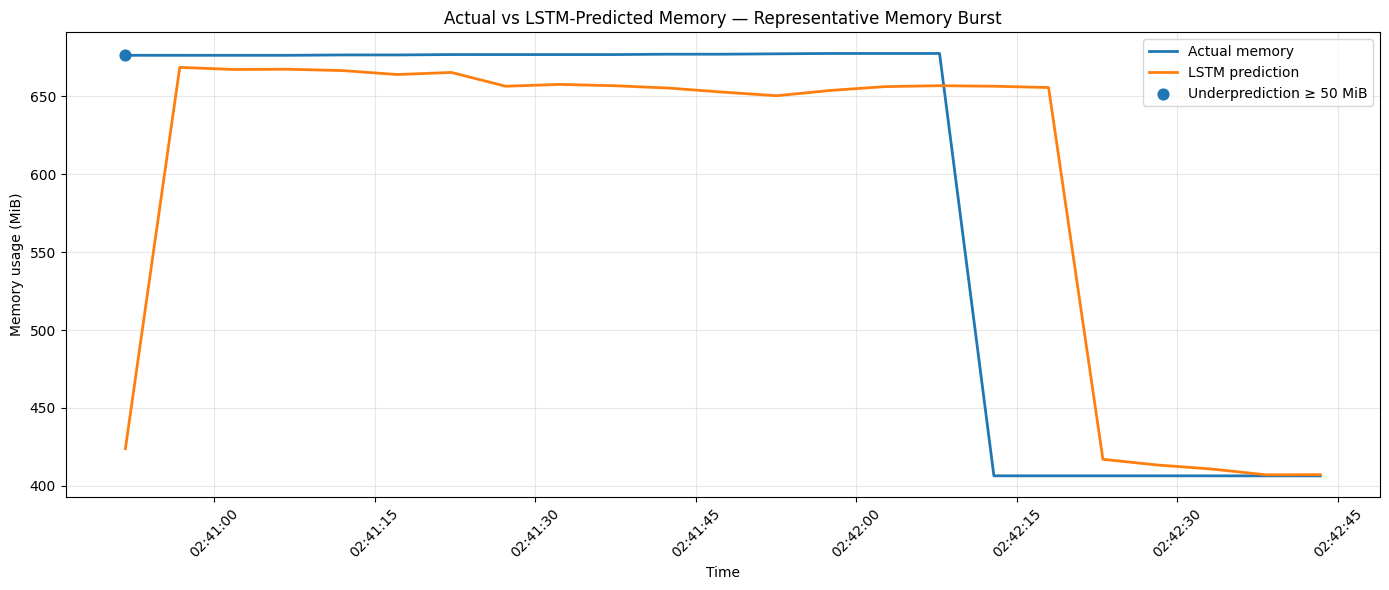


✅ VISUALIZATION COMPLETED


In [18]:
# ============================================================
# CELL 15 — ACTUAL vs PREDICTED MEMORY
# ============================================================

print("=" * 70)
print("ACTUAL vs PREDICTED MEMORY VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# Select one representative memory-burst experiment
# ------------------------------------------------------------

burst_diag = diagnostic_df[
    diagnostic_df["workload_profile"] == "memory_burst"
].copy()

# Pick an experiment containing one of the largest errors
largest_error_row = (
    burst_diag
    .sort_values(
        "underprediction_mib",
        ascending=False
    )
    .iloc[0]
)

selected_exp = largest_error_row["experiment_id"]
selected_vm = largest_error_row["vm_id"]

plot_df = burst_diag[
    (burst_diag["experiment_id"] == selected_exp) &
    (burst_diag["vm_id"] == selected_vm)
].copy()

plot_df = plot_df.sort_values("target_timestamp")

print(f"\nSelected VM         : {selected_vm}")
print(f"Selected experiment : {selected_exp}")
print(f"Samples             : {len(plot_df)}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["target_timestamp"],
    plot_df["actual_mib"],
    label="Actual memory",
    linewidth=2
)

plt.plot(
    plot_df["target_timestamp"],
    plot_df["predicted_mib"],
    label="LSTM prediction",
    linewidth=2
)

# Highlight large underpredictions

large_under = plot_df[
    plot_df["underprediction_mib"] >= 50
]

plt.scatter(
    large_under["target_timestamp"],
    large_under["actual_mib"],
    label="Underprediction ≥ 50 MiB",
    s=60,
    zorder=5
)

plt.xlabel("Time")
plt.ylabel("Memory usage (MiB)")
plt.title(
    "Actual vs LSTM-Predicted Memory — Representative Memory Burst"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

print("\n" + "=" * 70)
print("✅ VISUALIZATION COMPLETED")
print("=" * 70)

In [19]:
# ============================================================
# CELL 16 — SAFETY MARGIN ANALYSIS
# ============================================================

print("=" * 70)
print("SAFETY MARGIN ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Safety margins to evaluate
# ------------------------------------------------------------

SAFETY_MARGINS = [0, 25, 50, 75, 100, 150, 200]

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def evaluate_safety_margin(actual, prediction, margin):

    adjusted_prediction = prediction + margin

    error = adjusted_prediction - actual
    absolute_error = np.abs(error)

    underprediction = actual - adjusted_prediction

    return {
        "margin_mib": margin,

        "mae_mib": np.mean(absolute_error),

        "rmse_mib": np.sqrt(
            np.mean(error ** 2)
        ),

        "underprediction_rate_pct": (
            np.mean(underprediction > 0) * 100
        ),

        "under_50_rate_pct": (
            np.mean(underprediction > 50) * 100
        ),

        "under_100_rate_pct": (
            np.mean(underprediction > 100) * 100
        ),

        "under_150_rate_pct": (
            np.mean(underprediction > 150) * 100
        ),

        "mean_extra_prediction_mib": (
            np.mean(adjusted_prediction - prediction)
        )
    }

# ------------------------------------------------------------
# Overall test-set analysis
# ------------------------------------------------------------

overall_results = []

for margin in SAFETY_MARGINS:

    result = evaluate_safety_margin(
        y_test_mib,
        y_pred_mib,
        margin
    )

    overall_results.append(result)

overall_margin_df = pd.DataFrame(
    overall_results
)

print("\n" + "=" * 70)
print("OVERALL TEST SET")
print("=" * 70)

print(
    overall_margin_df.round(2).to_string(index=False)
)

# ------------------------------------------------------------
# Memory-burst analysis
# ------------------------------------------------------------

burst_mask = (
    test_predictions["workload_profile"]
    == "memory_burst"
).values

burst_actual = y_test_mib[burst_mask]
burst_prediction = y_pred_mib[burst_mask]

burst_results = []

for margin in SAFETY_MARGINS:

    result = evaluate_safety_margin(
        burst_actual,
        burst_prediction,
        margin
    )

    burst_results.append(result)

burst_margin_df = pd.DataFrame(
    burst_results
)

print("\n" + "=" * 70)
print("MEMORY-BURST TEST SET")
print("=" * 70)

print(
    burst_margin_df.round(2).to_string(index=False)
)

# ------------------------------------------------------------
# High-demand cases
# ------------------------------------------------------------

high_demand_mask = (
    y_test_mib >= 600
)

high_actual = y_test_mib[high_demand_mask]
high_prediction = y_pred_mib[high_demand_mask]

high_demand_results = []

for margin in SAFETY_MARGINS:

    adjusted_prediction = (
        high_prediction + margin
    )

    underprediction = (
        high_actual - adjusted_prediction
    )

    high_demand_results.append({
        "margin_mib": margin,
        "samples": len(high_actual),

        "underprediction_rate_pct": (
            np.mean(underprediction > 0) * 100
        ),

        "under_50_rate_pct": (
            np.mean(underprediction > 50) * 100
        ),

        "under_100_rate_pct": (
            np.mean(underprediction > 100) * 100
        ),

        "mean_underprediction_mib": (
            np.mean(
                np.maximum(
                    underprediction,
                    0
                )
            )
        )
    })

high_demand_df = pd.DataFrame(
    high_demand_results
)

print("\n" + "=" * 70)
print("HIGH-DEMAND CASES (ACTUAL >= 600 MiB)")
print("=" * 70)

print(
    high_demand_df.round(2).to_string(index=False)
)

# ------------------------------------------------------------
# Memory-burst high-demand cases
# ------------------------------------------------------------

burst_high_mask = (
    burst_actual >= 600
)

burst_high_actual = burst_actual[
    burst_high_mask
]

burst_high_prediction = burst_prediction[
    burst_high_mask
]

burst_high_results = []

for margin in SAFETY_MARGINS:

    adjusted_prediction = (
        burst_high_prediction + margin
    )

    underprediction = (
        burst_high_actual
        - adjusted_prediction
    )

    burst_high_results.append({
        "margin_mib": margin,
        "samples": len(burst_high_actual),

        "underprediction_rate_pct": (
            np.mean(underprediction > 0) * 100
        ),

        "under_50_rate_pct": (
            np.mean(underprediction > 50) * 100
        ),

        "under_100_rate_pct": (
            np.mean(underprediction > 100) * 100
        ),

        "mean_underprediction_mib": (
            np.mean(
                np.maximum(
                    underprediction,
                    0
                )
            )
        )
    })

burst_high_df = pd.DataFrame(
    burst_high_results
)

print("\n" + "=" * 70)
print("MEMORY-BURST HIGH-DEMAND CASES (ACTUAL >= 600 MiB)")
print("=" * 70)

print(
    burst_high_df.round(2).to_string(index=False)
)

print("\n" + "=" * 70)
print("✅ SAFETY MARGIN ANALYSIS COMPLETED")
print("=" * 70)

SAFETY MARGIN ANALYSIS

OVERALL TEST SET
 margin_mib    mae_mib   rmse_mib  underprediction_rate_pct  under_50_rate_pct  under_100_rate_pct  under_150_rate_pct  mean_extra_prediction_mib
          0  14.230000  34.959999                     42.55               1.65                1.18                0.75                        0.0
         25  30.150000  43.310001                      4.95               1.32                0.80                0.66                       25.0
         50  53.799999  61.480000                      1.65               1.18                0.75                0.42                       50.0
         75  78.070000  83.260002                      1.32               0.80                0.66                0.42                       75.0
        100 102.440002 106.470001                      1.18               0.75                0.42                0.05                      100.0
        150 151.550003 154.580002                      0.75               0.42     

In [20]:
# ============================================================
# CELL 17 — OFFLINE PROACTIVE DECISION ENGINE
# ============================================================

print("=" * 70)
print("OFFLINE PROACTIVE MEMORY DECISION ENGINE")
print("=" * 70)

# ------------------------------------------------------------
# Controller configuration
# ------------------------------------------------------------

SAFETY_MARGIN_MIB = 150

MIN_MEMORY_MIB = 512
MAX_MEMORY_MIB = 4096
MEMORY_STEP_MIB = 256

print("\nController configuration:")
print(f"Safety margin       : {SAFETY_MARGIN_MIB} MiB")
print(f"Minimum allocation  : {MIN_MEMORY_MIB} MiB")
print(f"Maximum allocation  : {MAX_MEMORY_MIB} MiB")
print(f"Allocation step     : {MEMORY_STEP_MIB} MiB")

# ------------------------------------------------------------
# Function: convert predicted usage into desired allocation
# ------------------------------------------------------------

def calculate_desired_allocation(
    predicted_memory_mib,
    safety_margin_mib=SAFETY_MARGIN_MIB,
    min_memory_mib=MIN_MEMORY_MIB,
    max_memory_mib=MAX_MEMORY_MIB,
    memory_step_mib=MEMORY_STEP_MIB
):
    """
    Convert predicted future memory usage into a
    proactive memory allocation recommendation.

    Steps:
    1. Add safety margin.
    2. Round UP to allocation granularity.
    3. Enforce min/max memory limits.
    """

    required_memory = (
        predicted_memory_mib
        + safety_margin_mib
    )

    # Round UP to the next allocation boundary
    desired_memory = (
        np.ceil(
            required_memory / memory_step_mib
        )
        * memory_step_mib
    )

    # Enforce controller limits
    desired_memory = np.clip(
        desired_memory,
        min_memory_mib,
        max_memory_mib
    )

    return desired_memory

# ------------------------------------------------------------
# Apply decision logic to the complete test set
# ------------------------------------------------------------

decision_df = diagnostic_df.copy()

decision_df["required_memory_mib"] = (
    decision_df["predicted_mib"]
    + SAFETY_MARGIN_MIB
)

decision_df["desired_allocation_mib"] = (
    decision_df["predicted_mib"]
    .apply(calculate_desired_allocation)
)

# ------------------------------------------------------------
# IMPORTANT:
# This is an OFFLINE recommendation.
#
# We are NOT pretending current_memory_mib is the VM's
# configured allocation. It represents observed guest usage.
# Actual libvirt allocation will be handled later.
# ------------------------------------------------------------

decision_df["allocation_headroom_mib"] = (
    decision_df["desired_allocation_mib"]
    - decision_df["actual_mib"]
)

# ------------------------------------------------------------
# Allocation recommendation statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ALLOCATION RECOMMENDATION STATISTICS")
print("=" * 70)

print(
    decision_df[
        [
            "predicted_mib",
            "required_memory_mib",
            "desired_allocation_mib",
            "actual_mib",
            "allocation_headroom_mib"
        ]
    ]
    .describe()
    .round(2)
    .to_string()
)

# ------------------------------------------------------------
# High-demand cases
# ------------------------------------------------------------

high_demand_decisions = decision_df[
    decision_df["actual_mib"] >= 600
].copy()

print("\n" + "=" * 70)
print("HIGH-DEMAND CASES — ACTUAL >= 600 MiB")
print("=" * 70)

print(
    high_demand_decisions[
        [
            "workload_profile",
            "actual_mib",
            "predicted_mib",
            "required_memory_mib",
            "desired_allocation_mib",
            "allocation_headroom_mib"
        ]
    ]
    .describe()
    .round(2)
    .to_string()
)

# ------------------------------------------------------------
# Memory-burst high-demand cases
# ------------------------------------------------------------

burst_high_decisions = decision_df[
    (decision_df["workload_profile"] == "memory_burst")
    &
    (decision_df["actual_mib"] >= 600)
].copy()

print("\n" + "=" * 70)
print("MEMORY-BURST HIGH-DEMAND CASES")
print("=" * 70)

print(
    burst_high_decisions[
        [
            "actual_mib",
            "predicted_mib",
            "required_memory_mib",
            "desired_allocation_mib",
            "allocation_headroom_mib"
        ]
    ]
    .describe()
    .round(2)
    .to_string()
)

# ------------------------------------------------------------
# Largest potential allocation requirements
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("10 HIGHEST PROACTIVE ALLOCATION RECOMMENDATIONS")
print("=" * 70)

print(
    decision_df[
        [
            "workload_profile",
            "actual_mib",
            "predicted_mib",
            "required_memory_mib",
            "desired_allocation_mib"
        ]
    ]
    .sort_values(
        "desired_allocation_mib",
        ascending=False
    )
    .head(10)
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Example decisions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXAMPLE DECISION LOGIC")
print("=" * 70)

example_predictions = [
    400,
    425,
    500,
    600,
    650,
    675
]

for prediction in example_predictions:

    required = (
        prediction
        + SAFETY_MARGIN_MIB
    )

    allocation = calculate_desired_allocation(
        prediction
    )

    print(
        f"Prediction: {prediction:>4} MiB "
        f"→ Required: {required:>4} MiB "
        f"→ Allocation: {allocation:>4} MiB"
    )

print("\n" + "=" * 70)
print("✅ OFFLINE DECISION ENGINE COMPLETED")
print("=" * 70)

OFFLINE PROACTIVE MEMORY DECISION ENGINE

Controller configuration:
Safety margin       : 150 MiB
Minimum allocation  : 512 MiB
Maximum allocation  : 4096 MiB
Allocation step     : 256 MiB

ALLOCATION RECOMMENDATION STATISTICS
       predicted_mib  required_memory_mib  desired_allocation_mib  actual_mib  allocation_headroom_mib
count        2120.00              2120.00                 2120.00     2120.00                  2120.00
mean          480.94               630.94                  805.80      480.37                   325.42
std            87.84                87.84                   90.84       90.45                    67.43
min           403.08               553.08                  768.00      399.98                    91.77
25%           418.28               568.28                  768.00      416.61                   334.00
50%           427.80               577.80                  768.00      423.91                   346.57
75%           547.14               697.14           

In [21]:
# ============================================================
# CELL 18 — CONTROLLER EFFICIENCY ANALYSIS
# ============================================================

print("=" * 70)
print("PROACTIVE CONTROLLER EFFICIENCY ANALYSIS")
print("=" * 70)

actual = decision_df["actual_mib"].values

# ------------------------------------------------------------
# Strategies
# ------------------------------------------------------------

static_512 = np.full_like(
    actual,
    512.0
)

static_768 = np.full_like(
    actual,
    768.0
)

lstm_policy = (
    decision_df["desired_allocation_mib"]
    .values
)

strategies = {
    "Static 512 MiB": static_512,
    "Static 768 MiB": static_768,
    "LSTM + 150 MiB": lstm_policy
}

# ------------------------------------------------------------
# Evaluate each strategy
# ------------------------------------------------------------

results = []

for name, allocation in strategies.items():

    headroom = allocation - actual

    underallocation = headroom < 0

    results.append({
        "strategy": name,
        "mean_allocation_mib": allocation.mean(),
        "max_allocation_mib": allocation.max(),
        "mean_headroom_mib": headroom.mean(),
        "max_headroom_mib": headroom.max(),

        "coverage_pct": (
            (~underallocation).mean() * 100
        ),

        "underallocation_events": (
            underallocation.sum()
        ),

        "underallocation_rate_pct": (
            underallocation.mean() * 100
        )
    })

efficiency_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("OVERALL CONTROLLER COMPARISON")
print("=" * 70)

print(
    efficiency_df.round(2).to_string(index=False)
)

# ------------------------------------------------------------
# Memory-burst comparison
# ------------------------------------------------------------

burst_mask = (
    decision_df["workload_profile"]
    == "memory_burst"
).values

burst_actual = actual[burst_mask]

burst_results = []

for name, allocation in strategies.items():

    burst_allocation = allocation[burst_mask]

    headroom = (
        burst_allocation
        - burst_actual
    )

    underallocation = headroom < 0

    burst_results.append({
        "strategy": name,

        "mean_allocation_mib": (
            burst_allocation.mean()
        ),

        "mean_headroom_mib": (
            headroom.mean()
        ),

        "coverage_pct": (
            (~underallocation).mean() * 100
        ),

        "underallocation_events": (
            underallocation.sum()
        ),

        "underallocation_rate_pct": (
            underallocation.mean() * 100
        )
    })

burst_efficiency_df = pd.DataFrame(
    burst_results
)

print("\n" + "=" * 70)
print("MEMORY-BURST CONTROLLER COMPARISON")
print("=" * 70)

print(
    burst_efficiency_df.round(2).to_string(index=False)
)

# ------------------------------------------------------------
# High-demand comparison
# ------------------------------------------------------------

high_mask = (
    actual >= 600
)

high_actual = actual[high_mask]

high_results = []

for name, allocation in strategies.items():

    high_allocation = allocation[high_mask]

    headroom = (
        high_allocation
        - high_actual
    )

    underallocation = headroom < 0

    high_results.append({
        "strategy": name,

        "mean_allocation_mib": (
            high_allocation.mean()
        ),

        "mean_headroom_mib": (
            headroom.mean()
        ),

        "coverage_pct": (
            (~underallocation).mean() * 100
        ),

        "underallocation_events": (
            underallocation.sum()
        )
    })

high_efficiency_df = pd.DataFrame(
    high_results
)

print("\n" + "=" * 70)
print("HIGH-DEMAND CONTROLLER COMPARISON")
print("=" * 70)

print(
    high_efficiency_df.round(2).to_string(index=False)
)

print("\n" + "=" * 70)
print("✅ CONTROLLER EFFICIENCY ANALYSIS COMPLETED")
print("=" * 70)

PROACTIVE CONTROLLER EFFICIENCY ANALYSIS

OVERALL CONTROLLER COMPARISON
      strategy  mean_allocation_mib  max_allocation_mib  mean_headroom_mib  max_headroom_mib  coverage_pct  underallocation_events  underallocation_rate_pct
Static 512 MiB                512.0               512.0              31.63            112.02         69.34                     650                     30.66
Static 768 MiB                768.0               768.0             287.63            368.02        100.00                       0                      0.00
LSTM + 150 MiB                805.8              1024.0             325.42            617.54        100.00                       0                      0.00

MEMORY-BURST CONTROLLER COMPARISON
      strategy  mean_allocation_mib  mean_headroom_mib  coverage_pct  underallocation_events  underallocation_rate_pct
Static 512 MiB               512.00             -33.38         38.36                     270                     61.64
Static 768 MiB            

In [22]:
# ============================================================
# CELL 19 — FIND MINIMUM FIXED SAFETY MARGIN FOR 100% COVERAGE
# ============================================================

print("=" * 70)
print("MINIMUM FIXED SAFETY MARGIN ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Required margin for every test prediction
# ------------------------------------------------------------

required_margin = (
    y_test_mib - y_pred_mib
)

# Only positive margins matter
required_margin = np.maximum(
    required_margin,
    0
)

# ------------------------------------------------------------
# Overall test set
# ------------------------------------------------------------

minimum_overall_margin = required_margin.max()

print(
    f"\nMinimum fixed margin for 100% "
    f"overall coverage: "
    f"{minimum_overall_margin:.2f} MiB"
)

# ------------------------------------------------------------
# Memory-burst
# ------------------------------------------------------------

burst_required_margin = np.maximum(
    burst_actual - burst_prediction,
    0
)

minimum_burst_margin = (
    burst_required_margin.max()
)

print(
    f"Minimum fixed margin for 100% "
    f"memory-burst coverage: "
    f"{minimum_burst_margin:.2f} MiB"
)

# ------------------------------------------------------------
# High-demand
# ------------------------------------------------------------

high_required_margin = np.maximum(
    high_actual - high_prediction,
    0
)

minimum_high_margin = (
    high_required_margin.max()
)

print(
    f"Minimum fixed margin for 100% "
    f"high-demand coverage: "
    f"{minimum_high_margin:.2f} MiB"
)

# ------------------------------------------------------------
# Memory-burst high-demand
# ------------------------------------------------------------

burst_high_required_margin = np.maximum(
    burst_high_actual - burst_high_prediction,
    0
)

minimum_burst_high_margin = (
    burst_high_required_margin.max()
)

print(
    f"Minimum fixed margin for 100% "
    f"memory-burst high-demand coverage: "
    f"{minimum_burst_high_margin:.2f} MiB"
)

# ------------------------------------------------------------
# Percentiles of required margin
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED MARGIN DISTRIBUTION")
print("=" * 70)

percentiles = [50, 75, 90, 95, 97.5, 99, 99.5, 100]

margin_distribution = pd.DataFrame({
    "percentile": percentiles,
    "overall_margin_mib": np.percentile(
        required_margin,
        percentiles
    ),
    "burst_margin_mib": np.percentile(
        burst_required_margin,
        percentiles
    ),
    "high_demand_margin_mib": np.percentile(
        high_required_margin,
        percentiles
    ),
    "burst_high_margin_mib": np.percentile(
        burst_high_required_margin,
        percentiles
    )
})

print(
    margin_distribution.round(2).to_string(index=False)
)

print("\n" + "=" * 70)
print("✅ MINIMUM MARGIN ANALYSIS COMPLETED")
print("=" * 70)

MINIMUM FIXED SAFETY MARGIN ANALYSIS

Minimum fixed margin for 100% overall coverage: 252.37 MiB
Minimum fixed margin for 100% memory-burst coverage: 252.37 MiB
Minimum fixed margin for 100% high-demand coverage: 252.37 MiB
Minimum fixed margin for 100% memory-burst high-demand coverage: 252.37 MiB

REQUIRED MARGIN DISTRIBUTION
 percentile  overall_margin_mib  burst_margin_mib  high_demand_margin_mib  burst_high_margin_mib
       50.0                0.00              1.83                   11.64                  16.01
       75.0                5.68             16.44                   19.03                  22.95
       90.0               17.81             25.89                   24.98                  40.71
       95.0               24.51            108.33                   57.09                 181.11
       97.5               36.09            179.93                  183.61                 244.21
       99.0              108.85            244.53                  245.61               

In [23]:
# ============================================================
# CELL 20 — SAFETY MARGIN TRADE-OFF ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("SAFETY MARGIN TRADE-OFF ANALYSIS")
print("=" * 75)

# Safety margins to evaluate
SAFETY_MARGINS = [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 252.37]

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------
def evaluate_margin(actual, predicted, margin):
    """
    Evaluate a fixed safety margin.

    Allocation = predicted memory + safety margin
    """

    allocated = predicted + margin

    errors = actual - allocated

    underallocated = errors > 0

    coverage = (~underallocated).mean() * 100

    mean_allocation = allocated.mean()

    mean_headroom = (allocated - actual).mean()

    max_underallocation = max(errors.max(), 0)

    return {
        "margin_mib": margin,
        "coverage_pct": coverage,
        "underalloc_count": underallocated.sum(),
        "underalloc_pct": underallocated.mean() * 100,
        "mean_allocation_mib": mean_allocation,
        "mean_headroom_mib": mean_headroom,
        "max_underallocation_mib": max_underallocation
    }


# ------------------------------------------------------------
# 1. Overall test set
# ------------------------------------------------------------

overall_results = []

for margin in SAFETY_MARGINS:
    result = evaluate_margin(
        y_test_mib,
        y_pred_mib,
        margin
    )
    overall_results.append(result)

overall_df = pd.DataFrame(overall_results)


# ------------------------------------------------------------
# 2. Memory-burst workload
# ------------------------------------------------------------

burst_results = []

for margin in SAFETY_MARGINS:
    result = evaluate_margin(
        burst_actual,
        burst_prediction,
        margin
    )
    burst_results.append(result)

burst_df = pd.DataFrame(burst_results)


# ------------------------------------------------------------
# 3. High-demand cases
# ------------------------------------------------------------

high_results = []

for margin in SAFETY_MARGINS:
    result = evaluate_margin(
        high_actual,
        high_prediction,
        margin
    )
    high_results.append(result)

high_df = pd.DataFrame(high_results)


# ------------------------------------------------------------
# 4. Memory-burst + high-demand
# ------------------------------------------------------------

burst_high_results = []

for margin in SAFETY_MARGINS:
    result = evaluate_margin(
        burst_high_actual,
        burst_high_prediction,
        margin
    )
    burst_high_results.append(result)

burst_high_df = pd.DataFrame(burst_high_results)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("OVERALL TEST SET")
print("=" * 75)

display(
    overall_df.round(2)
)


print("\n" + "=" * 75)
print("MEMORY-BURST WORKLOAD")
print("=" * 75)

display(
    burst_df.round(2)
)


print("\n" + "=" * 75)
print("HIGH-DEMAND CASES (Actual >= 600 MiB)")
print("=" * 75)

display(
    high_df.round(2)
)


print("\n" + "=" * 75)
print("MEMORY-BURST + HIGH-DEMAND")
print("=" * 75)

display(
    burst_high_df.round(2)
)


# ------------------------------------------------------------
# FIND BEST MARGIN WITH 100% COVERAGE
# ------------------------------------------------------------

def minimum_full_coverage(df):
    valid = df[df["coverage_pct"] >= 100]

    if len(valid) == 0:
        return None

    return valid.iloc[0]


print("\n" + "=" * 75)
print("100% COVERAGE CHECK")
print("=" * 75)

scenarios = {
    "Overall": overall_df,
    "Memory Burst": burst_df,
    "High Demand": high_df,
    "Burst + High Demand": burst_high_df
}

for name, result_df in scenarios.items():
    best = minimum_full_coverage(result_df)

    if best is not None:
        print(
            f"{name:25s}: "
            f"{best['margin_mib']:.2f} MiB margin | "
            f"Mean allocation = {best['mean_allocation_mib']:.2f} MiB"
        )
    else:
        print(f"{name:25s}: No margin achieved 100% coverage")


# ------------------------------------------------------------
# FIND EFFICIENT MARGIN
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EFFICIENCY INSIGHT")
print("=" * 75)

# Smallest margin giving at least 99% overall coverage
overall_99 = overall_df[
    overall_df["coverage_pct"] >= 99
]

if len(overall_99) > 0:
    best_99 = overall_99.iloc[0]

    print(
        f"Smallest margin for >=99% overall coverage: "
        f"{best_99['margin_mib']:.2f} MiB"
    )
    print(
        f"Coverage: {best_99['coverage_pct']:.2f}%"
    )
    print(
        f"Mean allocation: "
        f"{best_99['mean_allocation_mib']:.2f} MiB"
    )


# Smallest margin giving at least 99% burst coverage
burst_99 = burst_df[
    burst_df["coverage_pct"] >= 99
]

if len(burst_99) > 0:
    best_burst_99 = burst_99.iloc[0]

    print(
        f"\nSmallest margin for >=99% memory-burst coverage: "
        f"{best_burst_99['margin_mib']:.2f} MiB"
    )
    print(
        f"Coverage: {best_burst_99['coverage_pct']:.2f}%"
    )
    print(
        f"Mean allocation: "
        f"{best_burst_99['mean_allocation_mib']:.2f} MiB"
    )


print("\n" + "=" * 75)
print("✅ SAFETY MARGIN TRADE-OFF ANALYSIS COMPLETED")
print("=" * 75)

SAFETY MARGIN TRADE-OFF ANALYSIS

OVERALL TEST SET


,margin_mib,coverage_pct,underalloc_count,underalloc_pct,mean_allocation_mib,mean_headroom_mib,max_underallocation_mib
0,0.00,57.45,902,42.55,480.940002,0.570000,252.37
1,25.00,95.05,105,4.95,505.940002,25.570000,227.37
2,50.00,98.35,35,1.65,530.940002,50.570000,202.37
3,75.00,98.68,28,1.32,555.940002,75.570000,177.37
4,100.00,98.82,25,1.18,580.940002,100.570000,152.37
5,125.00,99.20,17,0.80,605.940002,125.570000,127.37
6,150.00,99.25,16,0.75,630.940002,150.570007,102.37
7,175.00,99.34,14,0.66,655.940002,175.570007,77.37
8,200.00,99.58,9,0.42,680.940002,200.570007,52.37
9,225.00,99.58,9,0.42,705.940002,225.570007,27.37



MEMORY-BURST WORKLOAD


,margin_mib,coverage_pct,underalloc_count,underalloc_pct,mean_allocation_mib,mean_headroom_mib,max_underallocation_mib
0,0.00,42.69,251,57.31,542.880005,-2.500000,252.37
1,25.00,89.50,46,10.50,567.880005,22.500000,227.37
2,50.00,92.92,31,7.08,592.880005,47.500000,202.37
3,75.00,93.84,27,6.16,617.880005,72.500000,177.37
4,100.00,94.29,25,5.71,642.880005,97.500000,152.37
5,125.00,96.12,17,3.88,667.880005,122.500000,127.37
6,150.00,96.35,16,3.65,692.880005,147.500000,102.37
7,175.00,96.80,14,3.20,717.880005,172.500000,77.37
8,200.00,97.95,9,2.05,742.880005,197.500000,52.37
9,225.00,97.95,9,2.05,767.880005,222.500000,27.37



HIGH-DEMAND CASES (Actual >= 600 MiB)


,margin_mib,coverage_pct,underalloc_count,underalloc_pct,mean_allocation_mib,mean_headroom_mib,max_underallocation_mib
0,0.00,25.97,268,74.03,630.390015,-17.420000,252.37
1,25.00,89.78,37,10.22,655.390015,7.580000,227.37
2,50.00,94.75,19,5.25,680.390015,32.580002,202.37
3,75.00,95.58,16,4.42,705.390015,57.580002,177.37
4,100.00,96.13,14,3.87,730.390015,82.580002,152.37
5,125.00,96.13,14,3.87,755.390015,107.580002,127.37
6,150.00,96.13,14,3.87,780.390015,132.580002,102.37
7,175.00,96.41,13,3.59,805.390015,157.580002,77.37
8,200.00,97.51,9,2.49,830.390015,182.580002,52.37
9,225.00,97.51,9,2.49,855.390015,207.580002,27.37



MEMORY-BURST + HIGH-DEMAND


,margin_mib,coverage_pct,underalloc_count,underalloc_pct,mean_allocation_mib,mean_headroom_mib,max_underallocation_mib
0,0.00,18.69,161,81.31,624.260010,-27.820000,252.37
1,25.00,83.33,33,16.67,649.260010,-2.820000,227.37
2,50.00,90.91,18,9.09,674.260010,22.180000,202.37
3,75.00,92.42,15,7.58,699.260010,47.180000,177.37
4,100.00,92.93,14,7.07,724.260010,72.180000,152.37
5,125.00,92.93,14,7.07,749.260010,97.180000,127.37
6,150.00,92.93,14,7.07,774.260010,122.180000,102.37
7,175.00,93.43,13,6.57,799.260010,147.179993,77.37
8,200.00,95.45,9,4.55,824.260010,172.179993,52.37
9,225.00,95.45,9,4.55,849.260010,197.179993,27.37



100% COVERAGE CHECK
Overall                  : 252.37 MiB margin | Mean allocation = 733.31 MiB
Memory Burst             : 252.37 MiB margin | Mean allocation = 795.25 MiB
High Demand              : 252.37 MiB margin | Mean allocation = 882.76 MiB
Burst + High Demand      : 252.37 MiB margin | Mean allocation = 876.63 MiB

EFFICIENCY INSIGHT
Smallest margin for >=99% overall coverage: 125.00 MiB
Coverage: 99.20%
Mean allocation: 605.94 MiB

Smallest margin for >=99% memory-burst coverage: 250.00 MiB
Coverage: 99.77%
Mean allocation: 792.88 MiB

✅ SAFETY MARGIN TRADE-OFF ANALYSIS COMPLETED


HIGH-MEMORY EVENT CLASSIFICATION

High-memory threshold: 600 MiB

OVERALL TEST SET
Accuracy  : 0.9542 (95.42%)
Precision : 0.8610 (86.10%)
Recall    : 0.8729 (87.29%)
F1-score  : 0.8669 (86.69%)

Confusion Matrix:
[[1707   51]
 [  46  316]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97      1758
 High Memory       0.86      0.87      0.87       362

    accuracy                           0.95      2120
   macro avg       0.92      0.92      0.92      2120
weighted avg       0.95      0.95      0.95      2120



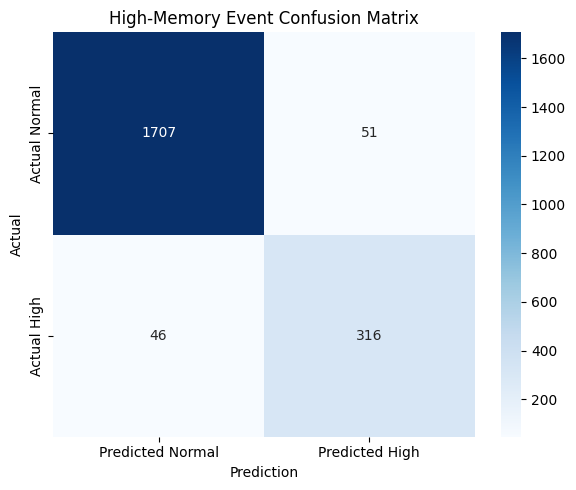


MEMORY-BURST WORKLOAD
Accuracy  : 0.8790 (87.90%)
Precision : 0.8836 (88.36%)
Recall    : 0.8434 (84.34%)
F1-score  : 0.8630 (86.30%)

Confusion Matrix:
[[218  22]
 [ 31 167]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      0.91      0.89       240
 High Memory       0.88      0.84      0.86       198

    accuracy                           0.88       438
   macro avg       0.88      0.88      0.88       438
weighted avg       0.88      0.88      0.88       438


SUMMARY


,Scenario,Accuracy,Precision,Recall,F1
0,Overall Test,0.9542,0.8610,0.8729,0.8669
1,Memory Burst,0.8790,0.8836,0.8434,0.8630



✅ HIGH-MEMORY CLASSIFICATION ANALYSIS COMPLETED


In [24]:
# ============================================================
# CELL 21 — HIGH-MEMORY EVENT CLASSIFICATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 75)
print("HIGH-MEMORY EVENT CLASSIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# Define threshold
# ------------------------------------------------------------

HIGH_MEMORY_THRESHOLD = 600  # MiB

print(f"\nHigh-memory threshold: {HIGH_MEMORY_THRESHOLD} MiB")


# ------------------------------------------------------------
# Overall test set
# ------------------------------------------------------------

actual_high = (y_test_mib >= HIGH_MEMORY_THRESHOLD).astype(int)
predicted_high = (y_pred_mib >= HIGH_MEMORY_THRESHOLD).astype(int)


accuracy = accuracy_score(actual_high, predicted_high)
precision = precision_score(actual_high, predicted_high, zero_division=0)
recall = recall_score(actual_high, predicted_high, zero_division=0)
f1 = f1_score(actual_high, predicted_high, zero_division=0)

cm = confusion_matrix(actual_high, predicted_high)


print("\n" + "=" * 75)
print("OVERALL TEST SET")
print("=" * 75)

print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score  : {f1:.4f} ({f1 * 100:.2f}%)")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        actual_high,
        predicted_high,
        target_names=["Normal", "High Memory"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion matrix visualization
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Normal", "Predicted High"],
    yticklabels=["Actual Normal", "Actual High"]
)

plt.title("High-Memory Event Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Memory-burst workload
# ------------------------------------------------------------

burst_actual_high = (
    burst_actual >= HIGH_MEMORY_THRESHOLD
).astype(int)

burst_predicted_high = (
    burst_prediction >= HIGH_MEMORY_THRESHOLD
).astype(int)


burst_accuracy = accuracy_score(
    burst_actual_high,
    burst_predicted_high
)

burst_precision = precision_score(
    burst_actual_high,
    burst_predicted_high,
    zero_division=0
)

burst_recall = recall_score(
    burst_actual_high,
    burst_predicted_high,
    zero_division=0
)

burst_f1 = f1_score(
    burst_actual_high,
    burst_predicted_high,
    zero_division=0
)

burst_cm = confusion_matrix(
    burst_actual_high,
    burst_predicted_high
)


print("\n" + "=" * 75)
print("MEMORY-BURST WORKLOAD")
print("=" * 75)

print(f"Accuracy  : {burst_accuracy:.4f} ({burst_accuracy * 100:.2f}%)")
print(f"Precision : {burst_precision:.4f} ({burst_precision * 100:.2f}%)")
print(f"Recall    : {burst_recall:.4f} ({burst_recall * 100:.2f}%)")
print(f"F1-score  : {burst_f1:.4f} ({burst_f1 * 100:.2f}%)")

print("\nConfusion Matrix:")
print(burst_cm)

print("\nClassification Report:")
print(
    classification_report(
        burst_actual_high,
        burst_predicted_high,
        target_names=["Normal", "High Memory"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

classification_results = pd.DataFrame({
    "Scenario": [
        "Overall Test",
        "Memory Burst"
    ],
    "Accuracy": [
        accuracy,
        burst_accuracy
    ],
    "Precision": [
        precision,
        burst_precision
    ],
    "Recall": [
        recall,
        burst_recall
    ],
    "F1": [
        f1,
        burst_f1
    ]
})

print("\n" + "=" * 75)
print("SUMMARY")
print("=" * 75)

display(
    classification_results.round(4)
)

print("\n" + "=" * 75)
print("✅ HIGH-MEMORY CLASSIFICATION ANALYSIS COMPLETED")
print("=" * 75)

In [25]:
# ============================================================
# CELL 22 — SAFETY-ADJUSTED HIGH-MEMORY EVENT DETECTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 75)
print("SAFETY-ADJUSTED HIGH-MEMORY EVENT DETECTION")
print("=" * 75)

HIGH_MEMORY_THRESHOLD = 600  # MiB

SAFETY_MARGINS = [
    0, 25, 50, 75, 100,
    125, 150, 175, 200,
    225, 250, 252.37
]

results = []

# Actual high-memory event
actual_high = (y_test_mib >= HIGH_MEMORY_THRESHOLD).astype(int)

for margin in SAFETY_MARGINS:

    # Safety-adjusted prediction
    adjusted_prediction = y_pred_mib + margin

    # Predicted high-memory event
    predicted_high = (
        adjusted_prediction >= HIGH_MEMORY_THRESHOLD
    ).astype(int)

    accuracy = accuracy_score(
        actual_high,
        predicted_high
    )

    precision = precision_score(
        actual_high,
        predicted_high,
        zero_division=0
    )

    recall = recall_score(
        actual_high,
        predicted_high,
        zero_division=0
    )

    f1 = f1_score(
        actual_high,
        predicted_high,
        zero_division=0
    )

    results.append({
        "safety_margin_mib": margin,
        "accuracy_pct": accuracy * 100,
        "precision_pct": precision * 100,
        "recall_pct": recall * 100,
        "f1_pct": f1 * 100
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("OVERALL TEST SET")
print("=" * 75)

display(
    results_df.round(2)
)


# ------------------------------------------------------------
# Memory-burst workload
# ------------------------------------------------------------

burst_results = []

burst_actual_high = (
    burst_actual >= HIGH_MEMORY_THRESHOLD
).astype(int)

for margin in SAFETY_MARGINS:

    adjusted_prediction = (
        burst_prediction + margin
    )

    predicted_high = (
        adjusted_prediction >= HIGH_MEMORY_THRESHOLD
    ).astype(int)

    accuracy = accuracy_score(
        burst_actual_high,
        predicted_high
    )

    precision = precision_score(
        burst_actual_high,
        predicted_high,
        zero_division=0
    )

    recall = recall_score(
        burst_actual_high,
        predicted_high,
        zero_division=0
    )

    f1 = f1_score(
        burst_actual_high,
        predicted_high,
        zero_division=0
    )

    burst_results.append({
        "safety_margin_mib": margin,
        "accuracy_pct": accuracy * 100,
        "precision_pct": precision * 100,
        "recall_pct": recall * 100,
        "f1_pct": f1 * 100
    })


burst_results_df = pd.DataFrame(burst_results)

print("\n" + "=" * 75)
print("MEMORY-BURST WORKLOAD")
print("=" * 75)

display(
    burst_results_df.round(2)
)


print("\n" + "=" * 75)
print("IMPORTANT")
print("=" * 75)

print(
    "These metrics evaluate whether the safety-adjusted prediction "
    "crosses the 600 MiB high-memory threshold."
)

print(
    "A larger safety margin can increase recall, but may also "
    "increase false positives and reduce precision."
)

print("\n" + "=" * 75)
print("✅ SAFETY-ADJUSTED CLASSIFICATION ANALYSIS COMPLETED")
print("=" * 75)

SAFETY-ADJUSTED HIGH-MEMORY EVENT DETECTION

OVERALL TEST SET


,safety_margin_mib,accuracy_pct,precision_pct,recall_pct,f1_pct
0,0.00,95.42,86.10,87.29,86.69
1,25.00,94.48,78.42,93.37,85.25
2,50.00,91.27,67.25,95.30,78.86
3,75.00,86.08,55.34,95.86,70.17
4,100.00,83.11,50.29,96.13,66.03
5,125.00,81.60,48.07,96.13,64.09
6,150.00,79.43,45.19,96.13,61.48
7,175.00,60.75,30.15,98.62,46.18
8,200.00,17.08,17.08,100.00,29.17
9,225.00,17.08,17.08,100.00,29.17



MEMORY-BURST WORKLOAD


,safety_margin_mib,accuracy_pct,precision_pct,recall_pct,f1_pct
0,0.00,87.90,88.36,84.34,86.30
1,25.00,86.99,83.73,88.38,86.00
2,50.00,86.53,80.89,91.92,86.05
3,75.00,78.08,69.17,92.93,79.31
4,100.00,76.26,67.15,92.93,77.97
5,125.00,76.03,66.91,92.93,77.80
6,150.00,75.80,66.67,92.93,77.64
7,175.00,73.52,63.49,97.47,76.89
8,200.00,45.21,45.21,100.00,62.26
9,225.00,45.21,45.21,100.00,62.26



IMPORTANT
These metrics evaluate whether the safety-adjusted prediction crosses the 600 MiB high-memory threshold.
A larger safety margin can increase recall, but may also increase false positives and reduce precision.

✅ SAFETY-ADJUSTED CLASSIFICATION ANALYSIS COMPLETED


In [26]:
# ============================================================
# CELL 23 — FINAL CONTROLLER POLICY COMPARISON
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("FINAL CONTROLLER POLICY COMPARISON")
print("=" * 75)


# ------------------------------------------------------------
# Controller evaluation function
# ------------------------------------------------------------

def evaluate_controller(actual, allocation):

    underallocation = np.maximum(actual - allocation, 0)
    headroom = allocation - actual

    coverage = np.mean(allocation >= actual) * 100

    return {
        "mean_allocation_mib": np.mean(allocation),
        "mean_headroom_mib": np.mean(headroom),
        "coverage_pct": coverage,
        "underalloc_count": np.sum(allocation < actual),
        "underalloc_pct": np.mean(allocation < actual) * 100,
        "mean_underallocation_mib": np.mean(underallocation),
        "max_underallocation_mib": np.max(underallocation),
        "mean_overallocation_mib": np.mean(np.maximum(headroom, 0))
    }


# ------------------------------------------------------------
# Controller policies
# ------------------------------------------------------------

policies = {}

# Static policies
policies["Static 512 MiB"] = np.full_like(
    y_test_mib,
    512.0
)

policies["Static 768 MiB"] = np.full_like(
    y_test_mib,
    768.0
)


# LSTM safety-margin policies
for margin in [125, 150, 200, 250, 252.37]:

    policies[f"LSTM + {margin:g} MiB"] = (
        y_pred_mib + margin
    )


# ------------------------------------------------------------
# Evaluate all policies
# ------------------------------------------------------------

results = []

for policy_name, allocation in policies.items():

    metrics = evaluate_controller(
        y_test_mib,
        allocation
    )

    metrics["policy"] = policy_name

    results.append(metrics)


controller_df = pd.DataFrame(results)

# Reorder columns
controller_df = controller_df[
    [
        "policy",
        "mean_allocation_mib",
        "mean_headroom_mib",
        "coverage_pct",
        "underalloc_count",
        "underalloc_pct",
        "mean_underallocation_mib",
        "max_underallocation_mib",
        "mean_overallocation_mib"
    ]
]


print("\n" + "=" * 75)
print("OVERALL TEST SET")
print("=" * 75)

display(
    controller_df.round(2)
)


# ------------------------------------------------------------
# Memory-burst evaluation
# ------------------------------------------------------------

burst_policies = {}

burst_policies["Static 512 MiB"] = np.full_like(
    burst_actual,
    512.0
)

burst_policies["Static 768 MiB"] = np.full_like(
    burst_actual,
    768.0
)

for margin in [125, 150, 200, 250, 252.37]:

    burst_policies[f"LSTM + {margin:g} MiB"] = (
        burst_prediction + margin
    )


burst_results = []

for policy_name, allocation in burst_policies.items():

    metrics = evaluate_controller(
        burst_actual,
        allocation
    )

    metrics["policy"] = policy_name

    burst_results.append(metrics)


burst_df_final = pd.DataFrame(burst_results)

burst_df_final = burst_df_final[
    [
        "policy",
        "mean_allocation_mib",
        "mean_headroom_mib",
        "coverage_pct",
        "underalloc_count",
        "underalloc_pct",
        "mean_underallocation_mib",
        "max_underallocation_mib",
        "mean_overallocation_mib"
    ]
]


print("\n" + "=" * 75)
print("MEMORY-BURST WORKLOAD")
print("=" * 75)

display(
    burst_df_final.round(2)
)


# ------------------------------------------------------------
# Identify 100% coverage policies
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("POLICIES WITH 100% TEST-SET COVERAGE")
print("=" * 75)

full_coverage = controller_df[
    controller_df["coverage_pct"] >= 100
].copy()

if len(full_coverage) > 0:

    display(
        full_coverage[
            [
                "policy",
                "mean_allocation_mib",
                "mean_headroom_mib",
                "coverage_pct"
            ]
        ].round(2)
    )

else:

    print("No policy achieved 100% coverage.")


print("\n" + "=" * 75)
print("✅ FINAL CONTROLLER POLICY COMPARISON COMPLETED")
print("=" * 75)

FINAL CONTROLLER POLICY COMPARISON

OVERALL TEST SET


,policy,mean_allocation_mib,mean_headroom_mib,coverage_pct,underalloc_count,underalloc_pct,mean_underallocation_mib,max_underallocation_mib,mean_overallocation_mib
0,Static 512 MiB,512.000000,31.629999,69.34,650,30.66,28.790001,165.410004,60.419998
1,Static 768 MiB,768.000000,287.630005,100.00,0,0.00,0.000000,0.000000,287.630005
2,LSTM + 125 MiB,605.940002,125.570000,99.20,17,0.80,0.690000,127.370003,126.260002
3,LSTM + 150 MiB,630.940002,150.570007,99.25,16,0.75,0.490000,102.370003,151.059998
4,LSTM + 200 MiB,680.940002,200.570007,99.58,9,0.42,0.190000,52.369999,200.759995
5,LSTM + 250 MiB,730.940002,250.570007,99.95,1,0.05,0.000000,2.370000,250.570007
6,LSTM + 252.37 MiB,733.309998,252.940002,100.00,0,0.00,0.000000,0.000000,252.940002



MEMORY-BURST WORKLOAD


,policy,mean_allocation_mib,mean_headroom_mib,coverage_pct,underalloc_count,underalloc_pct,mean_underallocation_mib,max_underallocation_mib,mean_overallocation_mib
0,Static 512 MiB,512.000000,-33.380001,38.36,270,61.64,69.550003,165.410004,36.169998
1,Static 768 MiB,768.000000,222.619995,100.00,0,0.00,0.000000,0.000000,222.619995
2,LSTM + 125 MiB,667.880005,122.500000,96.12,17,3.88,3.320000,127.370003,125.820000
3,LSTM + 150 MiB,692.880005,147.500000,96.35,16,3.65,2.370000,102.370003,149.869995
4,LSTM + 200 MiB,742.880005,197.500000,97.95,9,2.05,0.910000,52.369999,198.410004
5,LSTM + 250 MiB,792.880005,247.500000,99.77,1,0.23,0.010000,2.370000,247.500000
6,LSTM + 252.37 MiB,795.250000,249.869995,100.00,0,0.00,0.000000,0.000000,249.869995



POLICIES WITH 100% TEST-SET COVERAGE


,policy,mean_allocation_mib,mean_headroom_mib,coverage_pct
1,Static 768 MiB,768.000000,287.630005,100.0
6,LSTM + 252.37 MiB,733.309998,252.940002,100.0



✅ FINAL CONTROLLER POLICY COMPARISON COMPLETED


In [27]:
==========================================================================
FINAL CONTROLLER POLICY COMPARISON
===========================================================================

===========================================================================
OVERALL TEST SET
===========================================================================
policy	mean_allocation_mib	mean_headroom_mib	coverage_pct	underalloc_count	underalloc_pct	mean_underallocation_mib	max_underallocation_mib	mean_overallocation_mib
0	Static 512 MiB	512.000000	31.629999	69.34	650	30.66	28.790001	165.410004	60.419998
1	Static 768 MiB	768.000000	287.630005	100.00	0	0.00	0.000000	0.000000	287.630005
2	LSTM + 125 MiB	605.940002	125.570000	99.20	17	0.80	0.690000	127.370003	126.260002
3	LSTM + 150 MiB	630.940002	150.570007	99.25	16	0.75	0.490000	102.370003	151.059998
4	LSTM + 200 MiB	680.940002	200.570007	99.58	9	0.42	0.190000	52.369999	200.759995
5	LSTM + 250 MiB	730.940002	250.570007	99.95	1	0.05	0.000000	2.370000	250.570007
6	LSTM + 252.37 MiB	733.309998	252.940002	100.00	0	0.00	0.000000	0.000000	252.940002


===========================================================================
MEMORY-BURST WORKLOAD
===========================================================================
policy	mean_allocation_mib	mean_headroom_mib	coverage_pct	underalloc_count	underalloc_pct	mean_underallocation_mib	max_underallocation_mib	mean_overallocation_mib
0	Static 512 MiB	512.000000	-33.380001	38.36	270	61.64	69.550003	165.410004	36.169998
1	Static 768 MiB	768.000000	222.619995	100.00	0	0.00	0.000000	0.000000	222.619995
2	LSTM + 125 MiB	667.880005	122.500000	96.12	17	3.88	3.320000	127.370003	125.820000
3	LSTM + 150 MiB	692.880005	147.500000	96.35	16	3.65	2.370000	102.370003	149.869995
4	LSTM + 200 MiB	742.880005	197.500000	97.95	9	2.05	0.910000	52.369999	198.410004
5	LSTM + 250 MiB	792.880005	247.500000	99.77	1	0.23	0.010000	2.370000	247.500000
6	LSTM + 252.37 MiB	795.250000	249.869995	100.00	0	0.00	0.000000	0.000000	249.869995

===========================================================================
POLICIES WITH 100% TEST-SET COVERAGE
===========================================================================
policy	mean_allocation_mib	mean_headroom_mib	coverage_pct
1	Static 768 MiB	768.000000	287.630005	100.0
6	LSTM + 252.37 MiB	733.309998	252.940002	100.0

===========================================================================
✅ FINAL CONTROLLER POLICY COMPARISON COMPLETED


SyntaxError: invalid character '✅' (U+2705) (1815626202.py, line 38)

In [28]:
# ============================================================
# CELL 24 — REALISTIC ALLOCATION GRANULARITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("REALISTIC ALLOCATION GRANULARITY ANALYSIS")
print("=" * 75)

# Controller parameters
MIN_MEMORY_MIB = 512
MAX_MEMORY_MIB = 4096

SAFETY_MARGINS = [125, 150, 200, 250, 252.37]
ALLOCATION_STEPS = [64, 128, 256]


# ------------------------------------------------------------
# Allocation function
# ------------------------------------------------------------

def calculate_allocation(predictions, safety_margin, step):

    required_memory = predictions + safety_margin

    # Round UP to controller allocation granularity
    allocation = np.ceil(
        required_memory / step
    ) * step

    # Apply controller limits
    allocation = np.clip(
        allocation,
        MIN_MEMORY_MIB,
        MAX_MEMORY_MIB
    )

    return allocation


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_allocation(actual, allocation):

    underallocation = actual > allocation

    headroom = allocation - actual

    return {
        "mean_allocation_mib": np.mean(allocation),
        "mean_headroom_mib": np.mean(headroom),
        "coverage_pct": np.mean(~underallocation) * 100,
        "underalloc_count": np.sum(underallocation),
        "underalloc_pct": np.mean(underallocation) * 100,
        "max_underallocation_mib": max(
            np.max(actual - allocation),
            0
        )
    }


# ------------------------------------------------------------
# Overall test-set analysis
# ------------------------------------------------------------

overall_results = []

for step in ALLOCATION_STEPS:

    for margin in SAFETY_MARGINS:

        allocation = calculate_allocation(
            y_pred_mib,
            margin,
            step
        )

        metrics = evaluate_allocation(
            y_test_mib,
            allocation
        )

        metrics["allocation_step_mib"] = step
        metrics["safety_margin_mib"] = margin

        overall_results.append(metrics)


overall_granularity_df = pd.DataFrame(
    overall_results
)

overall_granularity_df = overall_granularity_df[
    [
        "allocation_step_mib",
        "safety_margin_mib",
        "mean_allocation_mib",
        "mean_headroom_mib",
        "coverage_pct",
        "underalloc_count",
        "underalloc_pct",
        "max_underallocation_mib"
    ]
]


print("\n" + "=" * 75)
print("OVERALL TEST SET")
print("=" * 75)

display(
    overall_granularity_df.round(2)
)


# ------------------------------------------------------------
# Memory-burst analysis
# ------------------------------------------------------------

burst_results = []

for step in ALLOCATION_STEPS:

    for margin in SAFETY_MARGINS:

        allocation = calculate_allocation(
            burst_prediction,
            margin,
            step
        )

        metrics = evaluate_allocation(
            burst_actual,
            allocation
        )

        metrics["allocation_step_mib"] = step
        metrics["safety_margin_mib"] = margin

        burst_results.append(metrics)


burst_granularity_df = pd.DataFrame(
    burst_results
)

burst_granularity_df = burst_granularity_df[
    [
        "allocation_step_mib",
        "safety_margin_mib",
        "mean_allocation_mib",
        "mean_headroom_mib",
        "coverage_pct",
        "underalloc_count",
        "underalloc_pct",
        "max_underallocation_mib"
    ]
]


print("\n" + "=" * 75)
print("MEMORY-BURST WORKLOAD")
print("=" * 75)

display(
    burst_granularity_df.round(2)
)


# ------------------------------------------------------------
# Find 100% coverage configurations
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("100% COVERAGE CONFIGURATIONS")
print("=" * 75)

full_coverage = overall_granularity_df[
    overall_granularity_df["coverage_pct"] >= 100
].copy()

if len(full_coverage) > 0:

    full_coverage = full_coverage.sort_values(
        "mean_allocation_mib"
    )

    display(
        full_coverage.round(2)
    )

else:

    print("No configuration achieved 100% coverage.")


# ------------------------------------------------------------
# Find most efficient 100% coverage configuration
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MOST MEMORY-EFFICIENT 100% COVERAGE CONFIGURATION")
print("=" * 75)

if len(full_coverage) > 0:

    best = full_coverage.iloc[0]

    print(
        f"Allocation step : "
        f"{best['allocation_step_mib']:.0f} MiB"
    )

    print(
        f"Safety margin   : "
        f"{best['safety_margin_mib']:.2f} MiB"
    )

    print(
        f"Mean allocation : "
        f"{best['mean_allocation_mib']:.2f} MiB"
    )

    print(
        f"Coverage        : "
        f"{best['coverage_pct']:.2f}%"
    )

    print(
        f"Underallocations: "
        f"{best['underalloc_count']:.0f}"
    )

print("\n" + "=" * 75)
print("ALLOCATION GRANULARITY ANALYSIS COMPLETED")
print("=" * 75)

REALISTIC ALLOCATION GRANULARITY ANALYSIS

OVERALL TEST SET


,allocation_step_mib,safety_margin_mib,mean_allocation_mib,mean_headroom_mib,coverage_pct,underalloc_count,underalloc_pct,max_underallocation_mib
0,64,125.00,637.950012,157.570007,99.20,17,0.80,100.23
1,64,150.00,656.630005,176.259995,99.48,11,0.52,100.23
2,64,200.00,705.900024,225.529999,99.58,9,0.42,36.23
3,64,250.00,764.559998,284.190002,100.00,0,0.00,0.00
4,64,252.37,765.830017,285.450012,100.00,0,0.00,0.00
5,128,125.00,692.530029,212.160004,99.58,9,0.42,36.23
6,128,150.00,701.580017,221.210007,99.58,9,0.42,36.23
7,128,200.00,714.989990,234.619995,99.58,9,0.42,36.23
8,128,250.00,819.020020,338.649994,100.00,0,0.00,0.00
9,128,252.37,820.409973,340.040009,100.00,0,0.00,0.00



MEMORY-BURST WORKLOAD


,allocation_step_mib,safety_margin_mib,mean_allocation_mib,mean_headroom_mib,coverage_pct,underalloc_count,underalloc_pct,max_underallocation_mib
0,64,125.00,705.609985,160.229996,96.12,17,3.88,100.23
1,64,150.00,715.539978,170.160004,97.49,11,2.51,100.23
2,64,200.00,773.109985,227.729996,97.95,9,2.05,36.23
3,64,250.00,831.419983,286.040009,100.00,0,0.00,0.00
4,64,252.37,833.609985,288.230011,100.00,0,0.00,0.00
5,128,125.00,759.229980,213.850006,97.95,9,2.05,36.23
6,128,150.00,768.880005,223.500000,97.95,9,2.05,36.23
7,128,200.00,782.900024,237.520004,97.95,9,2.05,36.23
8,128,250.00,883.429993,338.049988,100.00,0,0.00,0.00
9,128,252.37,887.229980,341.850006,100.00,0,0.00,0.00



100% COVERAGE CONFIGURATIONS


,allocation_step_mib,safety_margin_mib,mean_allocation_mib,mean_headroom_mib,coverage_pct,underalloc_count,underalloc_pct,max_underallocation_mib
3,64,250.00,764.559998,284.190002,100.0,0,0.0,0.0
4,64,252.37,765.830017,285.450012,100.0,0,0.0,0.0
10,256,125.00,794.929993,314.559998,100.0,0,0.0,0.0
11,256,150.00,805.799988,325.420013,100.0,0,0.0,0.0
8,128,250.00,819.020020,338.649994,100.0,0,0.0,0.0
9,128,252.37,820.409973,340.040009,100.0,0,0.0,0.0
12,256,200.00,822.099976,341.730011,100.0,0,0.0,0.0
13,256,250.00,845.520020,365.149994,100.0,0,0.0,0.0
14,256,252.37,846.010010,365.640015,100.0,0,0.0,0.0



MOST MEMORY-EFFICIENT 100% COVERAGE CONFIGURATION
Allocation step : 64 MiB
Safety margin   : 250.00 MiB
Mean allocation : 764.56 MiB
Coverage        : 100.00%
Underallocations: 0

ALLOCATION GRANULARITY ANALYSIS COMPLETED


In [29]:
# ============================================================
# CELL 25 — SAVE FINAL MODEL AND INFERENCE ARTIFACTS
# ============================================================

import os
import json
import joblib

print("=" * 75)
print("SAVING FINAL MODEL AND INFERENCE ARTIFACTS")
print("=" * 75)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

FINAL_CONFIG = {
    "model_type": "LSTM",

    "features": FEATURES,
    "target": TARGET,

    "sequence_length": SEQUENCE_LENGTH,
    "forecast_horizon": FORECAST_HORIZON,

    "feature_scaler": "RobustScaler",
    "target_scaler": "RobustScaler",

    "safety_margin_mib": 250.0,
    "allocation_step_mib": 64,

    "min_memory_mib": 512,
    "max_memory_mib": 4096,

    "high_memory_threshold_mib": 600,

    "test_metrics": {
        "mae_mib": 14.2251,
        "rmse_mib": 34.9595,
        "r2": 0.8505,
        "high_memory_accuracy": 0.9542,
        "high_memory_precision": 0.8610,
        "high_memory_recall": 0.8729,
        "high_memory_f1": 0.8669
    },

    "controller_test_metrics": {
        "coverage_pct": 100.0,
        "mean_allocation_mib": 764.56,
        "underallocations": 0
    }
}


# ------------------------------------------------------------
# Create artifact directory
# ------------------------------------------------------------

ARTIFACT_DIR = "/content/proactive_memory_artifacts"

os.makedirs(
    ARTIFACT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Save model
# ------------------------------------------------------------

MODEL_PATH = os.path.join(
    ARTIFACT_DIR,
    "best_proactive_memory_lstm.keras"
)

model.save(MODEL_PATH)


# ------------------------------------------------------------
# Save feature scaler
# ------------------------------------------------------------

FEATURE_SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "feature_scaler.pkl"
)

joblib.dump(
    feature_scaler,
    FEATURE_SCALER_PATH
)


# ------------------------------------------------------------
# Save target scaler
# ------------------------------------------------------------

TARGET_SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "target_scaler.pkl"
)

joblib.dump(
    target_scaler,
    TARGET_SCALER_PATH
)


# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

CONFIG_PATH = os.path.join(
    ARTIFACT_DIR,
    "model_config.json"
)

with open(
    CONFIG_PATH,
    "w"
) as f:

    json.dump(
        FINAL_CONFIG,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Verify files
# ------------------------------------------------------------

print("\nSaved artifacts:")

for filename in sorted(os.listdir(ARTIFACT_DIR)):

    filepath = os.path.join(
        ARTIFACT_DIR,
        filename
    )

    size_mb = os.path.getsize(filepath) / (
        1024 * 1024
    )

    print(
        f"  {filename:35s} "
        f"{size_mb:.2f} MB"
    )


print("\n" + "=" * 75)
print("FINAL CONFIGURATION")
print("=" * 75)

print(
    json.dumps(
        FINAL_CONFIG,
        indent=4
    )
)

print("\n" + "=" * 75)
print("MODEL AND INFERENCE ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 75)

SAVING FINAL MODEL AND INFERENCE ARTIFACTS

Saved artifacts:
  best_proactive_memory_lstm.keras    0.41 MB
  feature_scaler.pkl                  0.00 MB
  model_config.json                   0.00 MB
  target_scaler.pkl                   0.00 MB

FINAL CONFIGURATION
{
    "model_type": "LSTM",
    "features": [
        "guest_memory_used_mib",
        "cpu_utilization_pct"
    ],
    "target": "guest_memory_used_mib",
    "sequence_length": 6,
    "forecast_horizon": 2,
    "feature_scaler": "RobustScaler",
    "target_scaler": "RobustScaler",
    "safety_margin_mib": 250.0,
    "allocation_step_mib": 64,
    "min_memory_mib": 512,
    "max_memory_mib": 4096,
    "high_memory_threshold_mib": 600,
    "test_metrics": {
        "mae_mib": 14.2251,
        "rmse_mib": 34.9595,
        "r2": 0.8505,
        "high_memory_accuracy": 0.9542,
        "high_memory_precision": 0.861,
        "high_memory_recall": 0.8729,
        "high_memory_f1": 0.8669
    },
    "controller_test_metrics": {
   

In [30]:
# ============================================================
# CELL 26 — VERIFY SAVED MODEL RELOAD AND REPRODUCIBILITY
# ============================================================

import os
import json
import joblib
import numpy as np
import tensorflow as tf

print("=" * 75)
print("MODEL RELOAD AND REPRODUCIBILITY TEST")
print("=" * 75)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ARTIFACT_DIR = "/content/proactive_memory_artifacts"

MODEL_PATH = os.path.join(
    ARTIFACT_DIR,
    "best_proactive_memory_lstm.keras"
)

FEATURE_SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "feature_scaler.pkl"
)

TARGET_SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "target_scaler.pkl"
)

CONFIG_PATH = os.path.join(
    ARTIFACT_DIR,
    "model_config.json"
)


# ------------------------------------------------------------
# Load saved artifacts
# ------------------------------------------------------------

print("\nLoading saved artifacts...")

reloaded_model = tf.keras.models.load_model(
    MODEL_PATH
)

reloaded_feature_scaler = joblib.load(
    FEATURE_SCALER_PATH
)

reloaded_target_scaler = joblib.load(
    TARGET_SCALER_PATH
)

with open(CONFIG_PATH, "r") as f:
    reloaded_config = json.load(f)


print("Model loaded successfully.")
print("Feature scaler loaded successfully.")
print("Target scaler loaded successfully.")
print("Configuration loaded successfully.")


# ------------------------------------------------------------
# Compare model predictions
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PREDICTION REPRODUCIBILITY")
print("=" * 75)

# Use a subset of the already-created test sequences
N_CHECK = min(100, len(X_test))

X_check = X_test[:N_CHECK]

# Original trained model predictions
original_scaled = model.predict(
    X_check,
    verbose=0
).reshape(-1)

# Reloaded model predictions
reloaded_scaled = reloaded_model.predict(
    X_check,
    verbose=0
).reshape(-1)


# Convert back to MiB
original_mib = reloaded_target_scaler.inverse_transform(
    original_scaled.reshape(-1, 1)
).reshape(-1)

reloaded_mib = reloaded_target_scaler.inverse_transform(
    reloaded_scaled.reshape(-1, 1)
).reshape(-1)


# ------------------------------------------------------------
# Prediction differences
# ------------------------------------------------------------

prediction_difference = np.abs(
    original_mib - reloaded_mib
)

max_difference = np.max(
    prediction_difference
)

mean_difference = np.mean(
    prediction_difference
)


print(f"\nSamples checked: {N_CHECK}")
print(f"Maximum prediction difference: {max_difference:.10f} MiB")
print(f"Mean prediction difference:    {mean_difference:.10f} MiB")


# ------------------------------------------------------------
# Scaler verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SCALER VERIFICATION")
print("=" * 75)

feature_center_match = np.allclose(
    feature_scaler.center_,
    reloaded_feature_scaler.center_
)

feature_scale_match = np.allclose(
    feature_scaler.scale_,
    reloaded_feature_scaler.scale_
)

target_center_match = np.allclose(
    target_scaler.center_,
    reloaded_target_scaler.center_
)

target_scale_match = np.allclose(
    target_scaler.scale_,
    reloaded_target_scaler.scale_
)

print(
    f"Feature scaler center: "
    f"{'MATCH' if feature_center_match else 'MISMATCH'}"
)

print(
    f"Feature scaler scale:  "
    f"{'MATCH' if feature_scale_match else 'MISMATCH'}"
)

print(
    f"Target scaler center:  "
    f"{'MATCH' if target_center_match else 'MISMATCH'}"
)

print(
    f"Target scaler scale:   "
    f"{'MATCH' if target_scale_match else 'MISMATCH'}"
)


# ------------------------------------------------------------
# Configuration verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONFIGURATION VERIFICATION")
print("=" * 75)

print(
    "Features:",
    reloaded_config["features"]
)

print(
    "Sequence length:",
    reloaded_config["sequence_length"]
)

print(
    "Forecast horizon:",
    reloaded_config["forecast_horizon"]
)

print(
    "Safety margin:",
    reloaded_config["safety_margin_mib"],
    "MiB"
)

print(
    "Allocation step:",
    reloaded_config["allocation_step_mib"],
    "MiB"
)


# ------------------------------------------------------------
# Final pass/fail
# ------------------------------------------------------------

reproducibility_passed = (
    max_difference < 1e-5
    and feature_center_match
    and feature_scale_match
    and target_center_match
    and target_scale_match
)

print("\n" + "=" * 75)

if reproducibility_passed:
    print("✅ REPRODUCIBILITY TEST PASSED")
    print("Saved artifacts reproduce the original model predictions.")
else:
    print("❌ REPRODUCIBILITY TEST FAILED")
    print("Saved artifacts do not exactly match the original artifacts.")

print("=" * 75)

MODEL RELOAD AND REPRODUCIBILITY TEST

Loading saved artifacts...
Model loaded successfully.
Feature scaler loaded successfully.
Target scaler loaded successfully.
Configuration loaded successfully.

PREDICTION REPRODUCIBILITY



Samples checked: 100
Maximum prediction difference: 0.0000000000 MiB
Mean prediction difference:    0.0000000000 MiB

SCALER VERIFICATION
Feature scaler center: MATCH
Feature scaler scale:  MATCH
Target scaler center:  MATCH
Target scaler scale:   MATCH

CONFIGURATION VERIFICATION
Features: ['guest_memory_used_mib', 'cpu_utilization_pct']
Sequence length: 6
Forecast horizon: 2
Safety margin: 250.0 MiB
Allocation step: 64 MiB

✅ REPRODUCIBILITY TEST PASSED
Saved artifacts reproduce the original model predictions.


In [31]:
# ============================================================
# CELL 27 — LIVE INFERENCE CONTRACT TEST
# ============================================================

import os
import json
import joblib
import numpy as np
import tensorflow as tf

print("=" * 75)
print("LIVE INFERENCE CONTRACT TEST")
print("=" * 75)


# ------------------------------------------------------------
# 1. Load saved artifacts
# ------------------------------------------------------------

ARTIFACT_DIR = "/content/proactive_memory_artifacts"

MODEL_PATH = os.path.join(
    ARTIFACT_DIR,
    "best_proactive_memory_lstm.keras"
)

FEATURE_SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "feature_scaler.pkl"
)

TARGET_SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "target_scaler.pkl"
)

CONFIG_PATH = os.path.join(
    ARTIFACT_DIR,
    "model_config.json"
)

live_model = tf.keras.models.load_model(
    MODEL_PATH
)

live_feature_scaler = joblib.load(
    FEATURE_SCALER_PATH
)

live_target_scaler = joblib.load(
    TARGET_SCALER_PATH
)

with open(CONFIG_PATH, "r") as f:
    live_config = json.load(f)

print("Saved artifacts loaded successfully.")


# ------------------------------------------------------------
# 2. Extract one real test sequence
# ------------------------------------------------------------

# X_test is already scaled.
# Convert it back to the original telemetry units so that
# we can simulate receiving raw live telemetry.

sample_scaled = X_test[0]

sample_raw = live_feature_scaler.inverse_transform(
    sample_scaled
)

print("\n" + "=" * 75)
print("RAW TELEMETRY SEQUENCE")
print("=" * 75)

raw_sequence_df = pd.DataFrame(
    sample_raw,
    columns=live_config["features"]
)

display(
    raw_sequence_df.round(4)
)


# ------------------------------------------------------------
# 3. Simulate live preprocessing
# ------------------------------------------------------------

# In a real controller, these six raw observations would come
# from the VM telemetry collector.

live_scaled = live_feature_scaler.transform(
    raw_sequence_df[
        live_config["features"]
    ]
)

live_input = live_scaled.reshape(
    1,
    live_config["sequence_length"],
    len(live_config["features"])
)

print("\nScaled live input shape:")
print(live_input.shape)


# ------------------------------------------------------------
# 4. LSTM prediction
# ------------------------------------------------------------

predicted_scaled = live_model.predict(
    live_input,
    verbose=0
).reshape(-1, 1)

predicted_memory_mib = live_target_scaler.inverse_transform(
    predicted_scaled
)[0, 0]

print("\n" + "=" * 75)
print("LSTM PREDICTION")
print("=" * 75)

print(
    f"Predicted future memory: "
    f"{predicted_memory_mib:.2f} MiB"
)


# ------------------------------------------------------------
# 5. Apply safety margin
# ------------------------------------------------------------

safety_margin = live_config[
    "safety_margin_mib"
]

required_memory = (
    predicted_memory_mib +
    safety_margin
)

print("\n" + "=" * 75)
print("SAFETY ADJUSTMENT")
print("=" * 75)

print(
    f"Safety margin:       "
    f"{safety_margin:.2f} MiB"
)

print(
    f"Required memory:     "
    f"{required_memory:.2f} MiB"
)


# ------------------------------------------------------------
# 6. Apply allocation granularity
# ------------------------------------------------------------

allocation_step = live_config[
    "allocation_step_mib"
]

min_memory = live_config[
    "min_memory_mib"
]

max_memory = live_config[
    "max_memory_mib"
]

desired_allocation = (
    np.ceil(
        required_memory /
        allocation_step
    ) * allocation_step
)

desired_allocation = np.clip(
    desired_allocation,
    min_memory,
    max_memory
)


# ------------------------------------------------------------
# 7. Final proactive decision
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PROACTIVE MEMORY DECISION")
print("=" * 75)

print(
    f"Predicted memory : "
    f"{predicted_memory_mib:.2f} MiB"
)

print(
    f"Safety margin    : "
    f"{safety_margin:.2f} MiB"
)

print(
    f"Required memory  : "
    f"{required_memory:.2f} MiB"
)

print(
    f"Allocation step  : "
    f"{allocation_step:.0f} MiB"
)

print(
    f"Desired allocation: "
    f"{desired_allocation:.0f} MiB"
)


# ------------------------------------------------------------
# 8. Final validation
# ------------------------------------------------------------

assert live_input.shape == (
    1,
    live_config["sequence_length"],
    len(live_config["features"])
)

assert np.isfinite(
    predicted_memory_mib
)

assert desired_allocation >= min_memory

assert desired_allocation <= max_memory

assert (
    desired_allocation %
    allocation_step
) == 0


print("\n" + "=" * 75)
print("LIVE INFERENCE CONTRACT")
print("=" * 75)

print("Input features       :", live_config["features"])
print("Sequence length      :", live_config["sequence_length"])
print("Forecast horizon     :", live_config["forecast_horizon"])
print("Safety margin        :", safety_margin, "MiB")
print("Allocation granularity:", allocation_step, "MiB")

print("\n" + "=" * 75)
print("✅ LIVE INFERENCE CONTRACT TEST PASSED")
print("=" * 75)

LIVE INFERENCE CONTRACT TEST
Saved artifacts loaded successfully.

RAW TELEMETRY SEQUENCE


,guest_memory_used_mib,cpu_utilization_pct
0,421.535187,0.2577
1,421.781189,0.2847
2,421.531189,0.2681
3,421.527405,0.3197
4,421.527405,0.2391
5,421.511688,0.3481



Scaled live input shape:
(1, 6, 2)

LSTM PREDICTION
Predicted future memory: 427.08 MiB

SAFETY ADJUSTMENT
Safety margin:       250.00 MiB
Required memory:     677.08 MiB

PROACTIVE MEMORY DECISION
Predicted memory : 427.08 MiB
Safety margin    : 250.00 MiB
Required memory  : 677.08 MiB
Allocation step  : 64 MiB
Desired allocation: 704 MiB

LIVE INFERENCE CONTRACT
Input features       : ['guest_memory_used_mib', 'cpu_utilization_pct']
Sequence length      : 6
Forecast horizon     : 2
Safety margin        : 250.0 MiB
Allocation granularity: 64 MiB

✅ LIVE INFERENCE CONTRACT TEST PASSED


In [32]:
import shutil
import os

ARTIFACT_DIR = "/content/proactive_memory_artifacts"
ZIP_PATH = "/content/proactive_memory_artifacts"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    ARTIFACT_DIR
)

print("✅ Artifacts zipped successfully:")
print("/content/proactive_memory_artifacts.zip")

print("\nContents:")
for filename in sorted(os.listdir(ARTIFACT_DIR)):
    print(" -", filename)

✅ Artifacts zipped successfully:
/content/proactive_memory_artifacts.zip

Contents:
 - best_proactive_memory_lstm.keras
 - feature_scaler.pkl
 - model_config.json
 - target_scaler.pkl
